# 5 Markov Chain

## 5.1 Requirements

In [1]:
from pathlib import Path
import io
import base64
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import HTML, display
from scipy.stats import spearmanr, rankdata
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    roc_auc_score, roc_curve, log_loss, brier_score_loss, confusion_matrix,
    precision_recall_curve, average_precision_score,
)

## 5.2 Data

The chapter uses the processed Taiwan credit-card default data, which has already been divided into training, validation and test files. Every model uses the same three splits, so differences between models cannot be caused by differences in the data.

| Split | Customers | Default rate | Used for |
|---|---|---|---|
| Training | 17,997 | 22.1% | Fitting transition matrices, class priors and state-level default rates; setting the debt-bin edges |
| Validation | 5,999 | 22.1% | Platt scaling, choosing states, bins and hyperparameters, and screening models |
| Test | 5,999 | 22.1% | Held out: not used in any modelling decision |

There are 6 rows of month by month data which gives 5 transitions for each customer.

- **`PAY_6` ... `PAY_1`**: the repayment status in each month, these statuses are grouped into the Markov states.
- **`BILL_AMT6` ... `BILL_AMT1`** and **`LIMIT_BAL`**: the monthly bill and the customer's credit limit, which are combined into credit utilisation in Section 5.7.
- **`PAY_AMT6` ... `PAY_AMT1`**: the amount paid each month. 

In [2]:
ROOT = Path.cwd().parent
train      = pd.read_csv(ROOT / "data" / "processed" / "taiwan-train.csv", index_col="ID")
validation = pd.read_csv(ROOT / "data" / "processed" / "taiwan-validation.csv", index_col="ID")
test       = pd.read_csv(ROOT / "data" / "processed" / "taiwan-test.csv", index_col="ID")

TARGET = "default payment next month"
pay_cols  = [f"PAY_{i}" for i in range(6, 0, -1)]          # chronological Apr..Sep
bill_cols = [f"BILL_AMT{i}" for i in range(6, 0, -1)]
amt_cols  = [f"PAY_AMT{i}" for i in range(6, 0, -1)]

y_tr, y_va, y_te = train[TARGET].values, validation[TARGET].values, test[TARGET].values
print({k: (len(d), round(d[TARGET].mean(), 3)) for k, d in
       [("train", train), ("val", validation), ("test", test)]})

{'train': (17997, np.float64(0.221)), 'val': (5999, np.float64(0.221)), 'test': (5999, np.float64(0.221))}


## 5.3 Performance Metrics

Below are the functions for all the performance metrics that will be examined throughout this notebook. The metrics each can tell you something different about the model.
| Metric | Question it answers | Notes |
|---|---|---|
| ROC AUC, ROC curve | How does the model rank defaulters above non-defaulters at every threshold? | 0.5 is random ranking |
| Log loss, Brier score | Are confident predicted probabilities valid? | Lower is better; both penalise confident mistakes |
| Calibration curve | Do predicted probabilities match observed default rates? | Points on the diagonal are perfectly calibrated |
| Cumulative gains, precision-recall | How many defaulters are found if the highest-risk customers are targeted first? | Precision-recall is read against the 22.1% base rate |
| Confusion matrix | What mistakes does the model make at a particular cut-off? | Depends on the chosen threshold, so it illustrates trade-offs rather than ranking models |

In [3]:
ys = {"train": y_tr, "val": y_va}   # target arrays per split (test deliberately excluded)

_KEYS = {"train": ("p_tr", "sc_tr"), "val": ("p_va", "sc_va")}

def _probs(m, split):
    p_key, sc_key = _KEYS[split]          # KeyError if someone asks for "test"
    if p_key in m:
        return np.asarray(m[p_key])
    return m["platt"].predict_proba(np.asarray(m[sc_key]).reshape(-1, 1))[:, 1]

def _grid(n, ncols=2, size=(5, 4.5)):
    nrows = int(np.ceil(n / ncols)); ncols = min(n, ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows), squeeze=False)
    return fig, axs.ravel()

def _bar_by_split(models, values, title, ylabel, ylim=None):
    names, splits = list(models), list(next(iter(values.values())))
    w = 0.8 / len(splits); x = np.arange(len(names))
    fig, ax = plt.subplots(figsize=(1.8 * len(names) + 4, 4.5))
    for i, s in enumerate(splits):
        vals = [values[n][s] for n in names]
        bars = ax.bar(x + i * w - 0.4 + w / 2, vals, w, label=s)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x); ax.set_xticklabels(names, rotation=20, ha="right")
    ax.set_ylabel(ylabel); ax.set_title(title); ax.legend()
    if ylim: ax.set_ylim(*ylim)
    plt.tight_layout(); plt.show()

# ---------- one function per metric ----------

def plot_auc(models, ys=ys, splits=("train", "val")):
    vals = {n: {s: roc_auc_score(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    lo = min(v for d in vals.values() for v in d.values())
    _bar_by_split(models, vals, "ROC AUC", "AUC", ylim=(max(0.5, lo - 0.05), min(1, lo + 0.25)))
    return vals

def plot_logloss(models, ys=ys, splits=("train", "val")):
    vals = {n: {s: log_loss(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    _bar_by_split(models, vals, "Log loss (lower is better)", "log loss")
    return vals

def plot_brier(models, ys=ys, splits=("train", "val")):
    vals = {n: {s: brier_score_loss(ys[s], _probs(m, s)) for s in splits} for n, m in models.items()}
    _bar_by_split(models, vals, "Brier score (lower is better)", "Brier")
    return vals

def plot_roc(models, ys=ys, split="val"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        p = _probs(m, split)
        fpr, tpr, _ = roc_curve(ys[split], p)
        ax.plot(fpr, tpr, label=f"{n} (AUC {roc_auc_score(ys[split], p):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
    ax.set_title(f"ROC curves ({split})"); ax.legend(loc="lower right")
    plt.tight_layout(); plt.show()

def plot_pr(models, ys=ys, split="val"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        p_, r_, _ = precision_recall_curve(ys[split], _probs(m, split))
        ax.plot(r_, p_, label=f"{n} (AP {average_precision_score(ys[split], _probs(m, split)):.3f})")
    ax.axhline(np.mean(ys[split]), color="k", ls="--", lw=1, label="base rate")
    ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
    ax.set_title(f"Precision-recall ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_calibration(models, ys=ys, split="val", n_bins=10, strategy="quantile"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        frac, mean_p = calibration_curve(ys[split], _probs(m, split), n_bins=n_bins, strategy=strategy)
        ax.plot(mean_p, frac, "o-", label=n)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed default rate")
    ax.set_title(f"Calibration ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

def plot_gains(models, ys=ys, split="val"):
    fig, ax = plt.subplots(figsize=(6, 5.5))
    for n, m in models.items():
        y = np.asarray(ys[split]); order = np.argsort(-_probs(m, split))
        cum = np.cumsum(y[order]) / y.sum()
        ax.plot(np.arange(1, len(y) + 1) / len(y), cum, label=n)
    ax.plot([0, 1], [0, 1], "k--", lw=1)
    ax.set_xlabel("Fraction of customers (highest risk first)")
    ax.set_ylabel("Fraction of defaulters captured")
    ax.set_title(f"Cumulative gains ({split})"); ax.legend()
    plt.tight_layout(); plt.show()

# 5-to-1 cost ratio: assumes it is 5x more costly to miss a defaulter than to flag a non-defaulter.
def best_threshold(m, y_val, y_split="val", cost_fn=5, cost_fp=1):
    y = np.asarray(y_val)
    p = _probs(m, y_split)

    # Include all distinct operating points.
    fpr, tpr, thresholds = roc_curve(y, p, drop_intermediate=False)

    n_pos = np.sum(y == 1)
    n_neg = np.sum(y == 0)

    # FN = missed defaulters; FP = non-defaulters flagged.
    costs = cost_fn * n_pos * (1 - tpr) + cost_fp * n_neg * fpr

    return thresholds[np.argmin(costs)]

def plot_confusion(models, ys=ys, split="val", thresholds=None, normalize=True):
    fig, axs = _grid(len(models))
    for ax, (n, m) in zip(axs, models.items()):
        t = (best_threshold(m, ys["val"]) if thresholds is None
             else thresholds[n] if isinstance(thresholds, dict) else thresholds)
        pred = (_probs(m, split) >= t).astype(int)
        cm_ = confusion_matrix(ys[split], pred)
        show = cm_ / cm_.sum(1, keepdims=True) if normalize else cm_
        ax.imshow(show, cmap="Blues", vmin=0, vmax=show.max())
        for i in range(2):
            for j in range(2):
                ax.text(j, i, f"{cm_[i, j]:,}\n({show[i, j]:.0%})" if normalize else f"{cm_[i, j]:,}",
                        ha="center", va="center")
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(["pred 0", "pred 1"]); ax.set_yticklabels(["true 0", "true 1"])
        ax.set_title(f"{n}\nthreshold {t:.3f}")
    for ax in axs[len(models):]: ax.axis("off")
    fig.suptitle(f"Confusion matrices ({split})"); plt.tight_layout(); plt.show()

def show_row(*calls, width=330):
    imgs, _show = [], plt.show
    plt.show = lambda *a, **k: None
    try:
        for call in calls:
            call()
            fig = plt.gcf()
            buf = io.BytesIO()
            fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
            plt.close(fig)
            imgs.append(base64.b64encode(buf.getvalue()).decode())
    finally:
        plt.show = _show
    html = "".join(f"<img src='data:image/png;base64,{b}' style='width:{width}px'>" for b in imgs)
    display(HTML(f"<div style='display:flex;flex-wrap:wrap;gap:8px'>{html}</div>"))

## 5.4 Motivations

We decided to continue with a Markov chain because the payment data is already a time-ordered chain of each customer's behaviour. A chain naturally models the data as transitions between a fixed set of states. It is cheap to fit, requires minimal tuning, and can be interpreted directly. In the original model, defaulters and non-defaulters were pooled to create a single transition matrix. The first model was better than base-rate guessing (see Section 5.5.3 Log Loss: a constant 22.1% prediction gives about 0.528, against about 0.458 for the baseline on the validation set). However, it has several disadvantages, which we examine below so that we can identify ways to improve it. (Leow & Crook, 2014)

**Problems with the baseline**

1. **Pooling the classes.**
    - Pooling the two classes together hides the patterns of each class and averages their behaviour. This is why the next model will be trained on each class separately, so that their differences in behaviour can be better identified.
    - Averaging state transitions compresses extremes towards the mean, which leads to low risk being overestimated and high risk being underestimated. This is likely why the model does well on non-defaulters but is almost 50/50 on defaulters (see the confusion matrix in Section 5.5.3: validation set, threshold 0.344, recall 0.53, specificity 0.86).
2. **Compressed statuses.** The baseline maps the statuses -2, -1, and 0 to a single "current" state and merges every status of three or more months late into one state, which might be hiding information that could improve the model.
3. **Missing amounts.** Payment status does not give exact information about how large the late payments are. For example, £10 and £1,000 one month late are treated the same way.
4. **One-step memory.** The model is a one-step transition, so it only cares about the latest state. It treats someone who has been a month late for six months the same as someone who was current for the first five months and late only in the most recent one.

In this section, we will directly target each of these issues with adjustments to our model. Each adjustment is introduced in its own section below:

1. Firstly, creating a two-class chain so that class-specific patterns can be identified.
2. Varying the segmentation of states, merging states that carry little information while keeping those that distinguish the classes, so the transition estimates stay reliable.
3. Next, supplementing the chain with specific amounts by using the `BILL_AMT` and `PAY_AMT` data in conjunction.
4. Finally, using a higher-order Markov chain to allow dependence on more than just the previous state. (Malik & Thomas, 2012)

These adjustments all have trade-offs of their own, so they will not definitively improve the model. Changing the states will not always give an obviously correct segmentation. Defining states using `BILL_AMT` and `PAY_AMT`, or conditioning on more history, increases the number of rows in the transition matrix, so each row has fewer observations and its estimates become less reliable. This is why, as adjustments are made, it is important to compare against the baseline model to see how the results are affected, and to compare each model against one another to determine which is the most suitable for this problem. Metrics we will consider include AUC, log loss, Brier score, calibration, and stability between the training and validation sets.

## 5.5 Baseline Markov Chain Model

The code from the first sprint has been adjusted to fit our consistent split of data so that the comparisons are completely fair. This single-chain model is a good starting point because it is simple and computationally inexpensive, with only four states.

### 5.5.1 Model Definition

Let $s_{i,t}\in\{0,\dots,K-1\}$ be customer $i$'s state in month $t$ (with $K=4$), $s_{i,T}$ their latest state, $y_i\in\{0,1\}$ whether they default next month, and $\pi$ the training default rate. Everything below uses the training split only.

In [4]:
state_names = ["current", "1_month_late", "2_months_late", "3plus_months_late"]
K_ow = 4

def to_state_ow(p):
    p = np.asarray(p); s = np.empty(p.shape, dtype=int)
    s[p <= 0] = 0; s[p == 1] = 1; s[p == 2] = 2; s[p >= 3] = 3
    return s
S_tr = to_state_ow(train[pay_cols].values)
S_va = to_state_ow(validation[pay_cols].values)
S_te = to_state_ow(test[pay_cols].values)
y_tr_a, y_va_a, y_te_a = (np.asarray(v).astype(int) for v in (y_tr, y_va, y_te))

**1. Transition matrix with Laplace smoothing**

The probability for each entry is calculated with Laplace smoothing to prevent zero probabilities when the data is not substantial enough to justify them:
$$
P_{ab} \;=\; \frac{N_{ab}+1}{\sum_{b'} N_{ab'} + K},
\qquad
N_{ab} = \sum_i \sum_{t=1}^{T-1} \mathbf{1}\!\left[s_{i,t}=a,\; s_{i,t+1}=b\right]
$$

In [5]:
counts = np.ones((K_ow, K_ow))
for a, b in zip(S_tr[:, :-1].ravel(), S_tr[:, 1:].ravel()):
    counts[a, b] += 1
P_ow = counts / counts.sum(axis=1, keepdims=True)

**2. Default rate by latest state with shrinkage**

$$
r_k \;=\; \frac{\sum_i y_i\,\mathbf{1}\!\left[s_{i,T}=k\right] + \kappa\,\pi}{n_k + \kappa},
\qquad
n_k = \sum_i \mathbf{1}\!\left[s_{i,T}=k\right]
$$

where $\kappa$ is the shrinkage parameter (which acts like $\kappa$ extra customers with the average default rate, pulling the estimate towards the global rate).

In [6]:
latest_tr = S_tr[:, -1]
global_rate = y_tr_a.mean()
shrink = 20
risk_by_state = np.array([
    (y_tr_a[latest_tr == k].sum() + shrink * global_rate) / ((latest_tr == k).sum() + shrink)
    for k in range(K_ow)
])

**3. One-step Markov projection**

$$
\hat p_i \;=\; \sum_{j=0}^{K-1} P_{s_{i,T},\,j}\; r_j
$$

The predicted default probability is the expected default rate of next month's state, given the latest state.

In [7]:
def predict_onestep(S):
    return P_ow[S[:, -1]] @ risk_by_state
p_mk_onestep_va = predict_onestep(S_va)
p_mk_onestep_te = predict_onestep(S_te)
pooled = dict(p_tr=predict_onestep(S_tr), p_va=p_mk_onestep_va, p_te=p_mk_onestep_te)

### 5.5.2 Shrink Analysis

The only parameter requiring tuning in the baseline is the shrink value $\kappa$, which controls how strongly each state's default rate $r_k$ is pulled towards the global training default rate $\pi$. A larger $\kappa$ means more shrinkage; any states lacking in data are affected the most. We varied $\kappa$ between 0 and 2000 and evaluated each setting on the validation set:

| $\kappa$ | $r_0$ | $r_1$ | $r_2$ | $r_3$ | AUC | Log loss |
|---|---|---|---|---|---|---|
| 0 | 0.142 | 0.322 | 0.692 | 0.708 | 0.7098 | 0.4574 |
| 20 | 0.142 | 0.322 | 0.686 | 0.676 | 0.7098 | 0.4579 |
| 200 | 0.143 | 0.314 | 0.640 | 0.507 | 0.7098 | 0.4623 |
| 2000 | 0.152 | 0.274 | 0.430 | 0.282 | 0.7093 | 0.4835 |

AUC is almost unchanged across the whole range. The model produces only four distinct predictions (one per latest state), so AUC depends only on how those four values are ordered, and shrinkage barely alters that ordering. Log loss does change, and it rises as $\kappa$ increases, because heavy shrinkage pushes every state's risk towards the average and weakens the separation between states. The state 3+ rate falls fastest (0.708 to 0.282), which suggests it has far fewer customers than the others.

We chose $\kappa = 20$. It costs only about 0.0006 in log loss compared with no shrinkage, and it protects the estimate for the rarest state from being driven by a handful of customers. Because $\kappa$ was compared on the validation set, the test set was kept out of this choice.

In [8]:
for s in [0, 20, 200, 2000]:
    r = np.array([(y_tr_a[latest_tr == k].sum() + s * global_rate) /
                  ((latest_tr == k).sum() + s) for k in range(K_ow)])
    p = P_ow[S_va[:, -1]] @ r
    print(s, r.round(3), "order", np.argsort(r), "AUC", round(roc_auc_score(y_va_a, p), 5),
          "logloss", round(log_loss(y_va_a, p), 5))

0 [0.142 0.322 0.692 0.708] order [0 1 2 3] AUC 0.70983 logloss 0.45736
20 [0.142 0.322 0.686 0.676] order [0 1 3 2] AUC 0.70983 logloss 0.45792
200 [0.143 0.314 0.64  0.507] order [0 1 3 2] AUC 0.70983 logloss 0.46225
2000 [0.152 0.274 0.43  0.282] order [0 1 3 2] AUC 0.70931 logloss 0.48346


### 5.5.3 Performance

We evaluate the baseline on the training and validation splits and compare it with a constant prediction of the training default rate (22.1%).

| | Constant 22.1% | Baseline (train) | Baseline (val) | 
|---|---|---|---|
| Log loss | ≈ 0.528 | 0.465 | 0.458 | 
| Brier score | ≈ 0.172 | 0.147 | 0.144 | 
| AUC | 0.5 | 0.692 | 0.710 | 


The baseline clearly improves on guessing, and its scores are close across the splits, so the result is stable. With only a 4×4 matrix and four rates, the model has too few parameters to overfit, so this is expected rather than strong evidence of generalisation. 

At the validation-chosen threshold of 0.344 (chosen assuming that missing a defaulter costs five times as much as wrongly flagging a non-defaulter, which is an assumption rather than a known cost), the confusion matrix gives a recall of 0.53, a specificity of 0.86, and a precision of about 0.52. The model therefore clears most non-defaulters but misses around 47% of defaulters. The baseline ranks customers reasonably well (validation AUC ≈ 0.71), but its probabilities are not well calibrated at the extremes: the calibration curve below shows low-risk customers being overestimated (predicted ≈ 0.17, observed ≈ 0.13) and high-risk customers underestimated (predicted ≈ 0.51, observed ≈ 0.71). This backs up the claim from Section 5.4. Since AUC only measures whether defaulters are scored above non-defaulters (as opposed to whether the predicted probabilities match observed default rates), we must also report log loss and Brier score, which penalise poorly calibrated probabilities.

These results are the reference point for the models that follow.


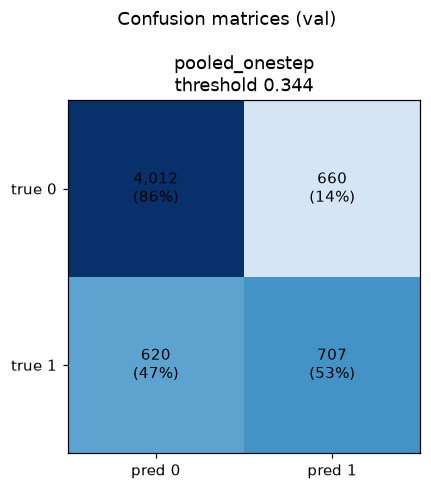
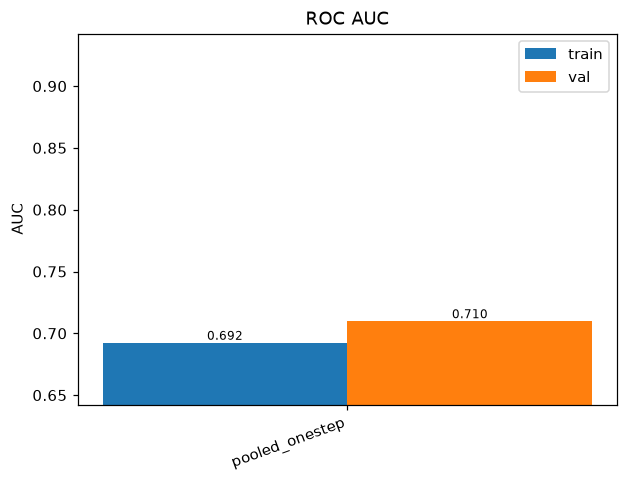
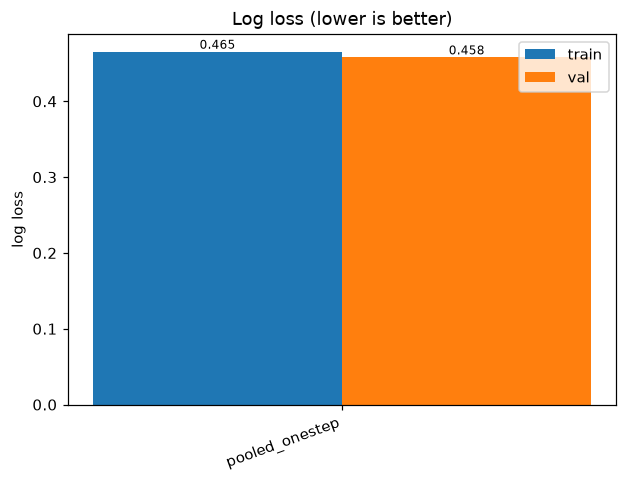
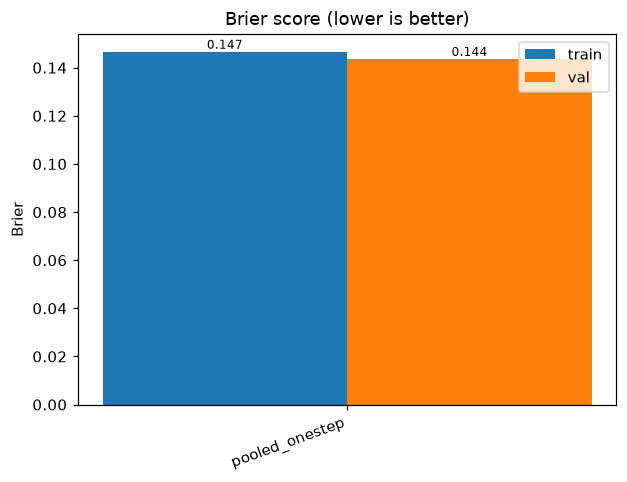
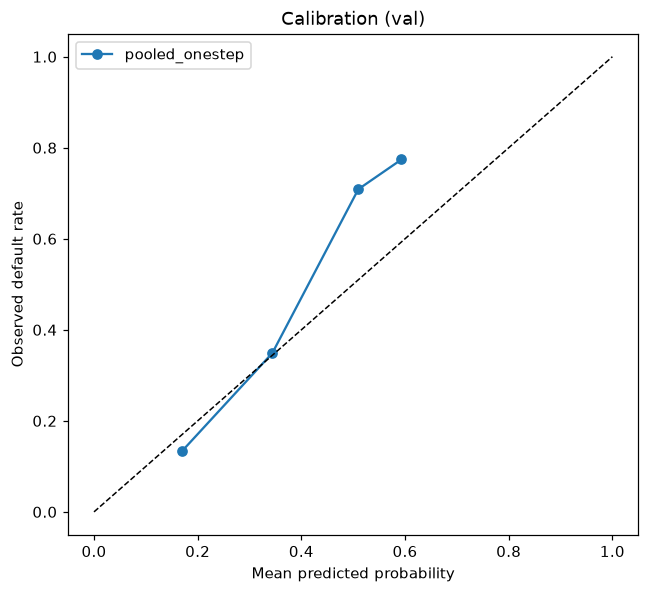

In [9]:
m = {"pooled_onestep": pooled}
show_row(
    lambda: plot_confusion(m, split="val"),
    lambda: plot_auc(m),
    lambda: plot_logloss(m),
    lambda: plot_brier(m),
    lambda: plot_calibration(m, split="val"),
)

## 5.6 Two-Class Chain

For the next model, we will fit a separate chain for defaulters and non-defaulters and compare how the two classes behave. For this model, the training data is separated into default and non-default classes, and a Markov chain is fitted to each of them.

### 5.6.1 Constructing the Model

**1. Data and states**

For each customer, $(\text{PAY}_6, \dots, \text{PAY}_1)$ denotes their payment status history and $y \in \{0, 1\}$ denotes default ($1$ = default next month). The state mappings assign each status to a bin:

$$x_t = g(\text{PAY}_t) \in \{1, \dots, K\}, \qquad \mathbf{x} = (x_1, x_2, \dots, x_T).$$

For the new two-class model, we will fit it with different state bins, which we can then compare to see how they affect the results. The first mapping gives a 5-state chain, while the second gives a 4-state chain by merging the non-late statuses and splitting the final late state into two.

**2. Fit one chain per class**
Let $\mathcal{D}_c = \{ i : y_i = c \}$ for $c \in \{0, 1\}$ and let $\alpha = 1$ be the Laplace constant.

**Initial distribution** (state in the first month):

$$\pi_c(s) = \frac{\alpha + \sum_{i \in \mathcal{D}_c} \mathbf{1}[x_{i,1} = s]}{|\mathcal{D}_c| + K\alpha}.$$

**Transition matrix** from pooled consecutive pairs:

$$N_c(a,b) = \sum_{i \in \mathcal{D}_c} \sum_{t=1}^{T-1} \mathbf{1}[x_{i,t} = a,\; x_{i,t+1} = b],$$

$$P_c(a,b) = \frac{N_c(a,b) + \alpha}{\sum_{b'} N_c(a,b') + K\alpha}, \qquad \sum_{b} P_c(a,b) = 1.$$

In [10]:
# ---- generic Markov model ----
def fit_chain(S, K, alpha=1.0):
    init = np.bincount(S[:, 0], minlength=K) + alpha; init = init / init.sum()
    C = np.zeros((K, K)) + alpha
    for a, b in zip(S[:, :-1].ravel(), S[:, 1:].ravel()): C[a, b] += 1
    return init, C / C.sum(axis=1, keepdims=True)

def llr(S, m):
    sc = np.log(m["init1"][S[:, 0]]) - np.log(m["init0"][S[:, 0]])
    for t in range(S.shape[1] - 1):
        sc += np.log(m["P1"][S[:, t], S[:, t+1]]) - np.log(m["P0"][S[:, t], S[:, t+1]])
    return sc + m["log_prior"]

def build_markov(name, to_state, K):
    S_tr, S_va, S_te = (to_state(d[pay_cols].values) for d in (train, validation, test))
    #------2. Fit the Markov chain to the training data for each class (default and non-default)-------# 
    init0, P0 = fit_chain(S_tr[y_tr == 0], K)      # TRAIN only
    init1, P1 = fit_chain(S_tr[y_tr == 1], K)
    m = dict(name=name, K=K, to_state=to_state, init0=init0, P0=P0, init1=init1, P1=P1,
             log_prior=np.log(y_tr.mean() / (1 - y_tr.mean())))
    m["sc_tr"], m["sc_va"], m["sc_te"] = llr(S_tr, m), llr(S_va, m), llr(S_te, m)
    
    #--------5. Fit a Platt scaling model to the validation set to calibrate the scores into probabilities.----------#
    m["platt"] = LogisticRegression(C=1e6).fit(m["sc_va"].reshape(-1, 1), y_va)   # VALIDATION
    m["p_va"] = m["platt"].predict_proba(m["sc_va"].reshape(-1, 1))[:, 1]
    m["p_te"] = m["platt"].predict_proba(m["sc_te"].reshape(-1, 1))[:, 1]
    return m



**3. Sequence likelihood under each class**

Assuming a first-order, time-homogeneous Markov chain:

$$\Pr(\mathbf{x} \mid y = c) = \pi_c(x_1) \prod_{t=1}^{T-1} P_c(x_t, x_{t+1}).$$

**4. Posterior odds (Bayes' rule)**

With prior $\hat{p} = \Pr(y = 1)$ estimated on train:

$$\frac{\Pr(y=1 \mid \mathbf{x})}{\Pr(y=0 \mid \mathbf{x})}
= \frac{\Pr(\mathbf{x} \mid y=1)}{\Pr(\mathbf{x} \mid y=0)} \cdot \frac{\hat{p}}{1-\hat{p}}.$$

Taking logs gives the score used in the code (`llr`):

$$s(\mathbf{x}) = \underbrace{\log\frac{\pi_1(x_1)}{\pi_0(x_1)}}_{\text{start}}
+ \sum_{t=1}^{T-1} \underbrace{\log\frac{P_1(x_t, x_{t+1})}{P_0(x_t, x_{t+1})}}_{\text{transition } t}
+ \underbrace{\log\frac{\hat{p}}{1-\hat{p}}}_{\text{prior}}.$$

Each transition contributes its log-ratio $\ell(a,b) = \log P_1(a,b) - \log P_0(a,b)$, the quantity shown in the log-ratio heatmap. $\ell > 0$ pushes towards default; $\ell < 0$ pushes away.

**5. Calibration (validation split)**

The chain's independence assumptions make $s$ overconfident, so $s$ is mapped to a probability by logistic (Platt) scaling fitted on the **validation** set:

$$\Pr(y = 1 \mid \mathbf{x}) = \sigma\big(a\, s(\mathbf{x}) + b\big), \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

If $a = 1$ and $b = 0$, this reduces to the exact Bayes posterior.

**6. Assumptions and limitations**

- **First order:** $x_{t+1}$ depends only on $x_t$, not on earlier history.
- **Time-homogeneous:** the same $P_c$ applies at every step.
- **Sparse classes:** defaulters are about 22% of the data, so $P_1$ rests on fewer transitions. Rows with small $\sum_b N_c(a,b)$ are dominated by $\alpha$.
- **Leakage control:** $\pi_c, P_c, \hat{p}$ use train only; $(a, b)$ uses validation only; test is held out for evaluation.

### 5.6.2 Choosing States

Now that we have our model, we need to consider the different ways in which we can split the states. We looked at six ways of grouping the `PAY` statuses into Markov states. Comparing all six in detail would be excessive, so only the three most interesting splits are examined thoroughly in this chapter. The choices we made are as follows:

| Split | States | K | Val Brier | Decision |
|---|---|---|---|---|
| `mk5_full` | −2 · −1 · 0 · 1 · 2+ | 5 | 0.1391 | **Kept** |
| `mk4_nolate` | {−2, −1, 0} · 1 · 2 · 3+ | 4 | 0.1392 | **Kept** |
| `mk4_12` | {−2, −1} · 0 · {1, 2} · 3+ | 4 | 0.1405 | **Kept** |
| `mk4_01` | −2 · −1 · {0, 1} · 2+ | 4 | 0.1395 | Dropped |
| `mk5_12` | −2 · −1 · 0 · {1, 2} · 3+ | 5 | 0.1406 | Dropped |
| `mk4_late` | −2 · −1 · 0 · 1+ | 4 | 0.1407 | Dropped |


**Why the three were kept**

The kept splits give two interesting comparisons:

- **`mk5_full` vs `mk4_nolate`:** does separating the not-late statuses (no bill, paid, revolving) matter? Their scores are almost identical, so the finer split may add little information.
- **`mk4_nolate` vs `mk4_12`:** does merging the 1- and 2-months-late states, which fixes the sparse "1 late" row, cost predictive accuracy? It costs about 0.0013 in validation Brier score.

**Why the other three were dropped**

- **`mk4_01`:** it merges revolving credit (0) with one month late (1), which puts an on-time status together with a late one. The result is also behind the two best splits on validation.
- **`mk4_late`:** it merges every late status into one state, losing the difference between 1, 2, and 3+ months late. It has the worst validation score of the six.
- **`mk5_12`:** it performs essentially the same as `mk4_12` (0.1406 vs 0.1405) but has an extra state and therefore sparser rows, so the 4-state version replaces it.

**Selection rule and caveats**

Splits were removed using validation results and the reasoning above, so the test set stays unseen. The differences between splits are small (about 0.0001 to 0.0016 in Brier score from the best split), and we have not yet tested whether they are larger than sampling noise. Dropping these splits is therefore a simplification rather than a claim that they are provably worse. Where scores are indistinguishable, we prefer fewer states and better data support per transition.

In [11]:
# raw PAY value -> state; every value >= top goes to the final state
STATE_SPECS = {
    "mk5_full":   dict(map={-2:0,-1:1,0:2,1:3},     top=2, labels=["no bill","paid","revolving","1 late","2+ late"]),
    "mk4_nolate": dict(map={-2:0,-1:0,0:0,1:1,2:2}, top=3, labels=["on time","1 late","2 late","3+ late"]),
    "mk4_12":     dict(map={-2:0,-1:0,0:1,1:2,2:2}, top=3, labels=["no bill/paid","revolving","1-2 late","3+ late"]),
}

def _to_state_fn(mapping, top):
    last = max(mapping.values()) + 1
    raw_vals = list(mapping)
    def f(p):
        p = np.asarray(p)
        s = np.full(p.shape, last, dtype=int)
        for raw, st in mapping.items():
            s[p == raw] = st
        bad = (p < top) & ~np.isin(p, raw_vals)
        if bad.any():
            raise ValueError(f"unmapped PAY values: {np.unique(p[bad])}")
        return s
    return f

def make_all_states(specs=STATE_SPECS):
    out = {}
    for name, sp in specs.items():
        K = max(sp["map"].values()) + 2          # mapped states + one final "top" state
        labels = sp.get("labels")
        if labels is not None and len(labels) != K:
            raise ValueError(f"{name}: {len(labels)} labels but K={K}")
        out[name] = dict(to_state=_to_state_fn(sp["map"], sp["top"]), K=K, labels=labels)
    return out

states = make_all_states()
markov_models = {n: build_markov(n, s["to_state"], s["K"]) for n, s in states.items()}
labels_all    = {n: s["labels"] for n, s in states.items()}

### 5.6.3 Matrix Heatmaps

The two-class chain is defined by two transition matrices, $P_0$ for non-defaulters and $P_1$ for defaulters. By plotting them, we can check whether the model has learned behaviour that sounds reasonable and where its estimates can be trusted. For each state split, we show four panels:

- **$P_0$ and $P_1$:** the probability of moving from this month's state (rows) to next month's state (columns) for each class. Strong diagonals mean customers tend to stay in the same state.
- **$P_1 - P_0$:** the difference between the classes. Positive (red) cells are moves that defaulters make more often, while negative (blue) cells show moves more likely to be made by non-defaulters.
- **$\log(P_1/P_0)$:** the contribution of each transition to the model's score (the log-likelihood ratio). Positive values push a customer's score towards default, and negative values push it away. Cells with fewer than 30 observed transitions in either class are greyed out as unreliable.

Because a probability estimated from few observations can be misleading, we follow each set of heatmaps with count heatmaps showing how many transitions each cell is based on and how many customers leave each state. Rows with very few transitions are flagged; these are the main reason for merging states in the next section.

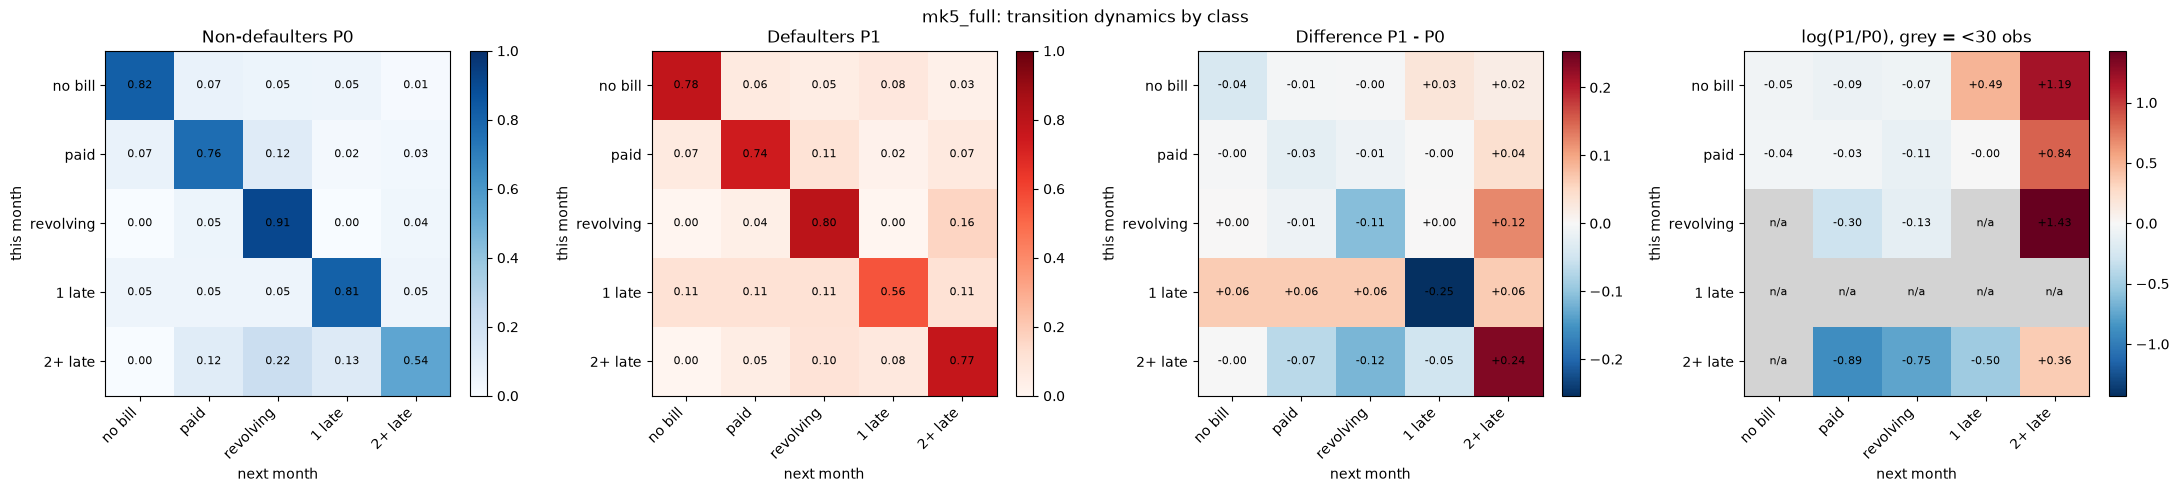

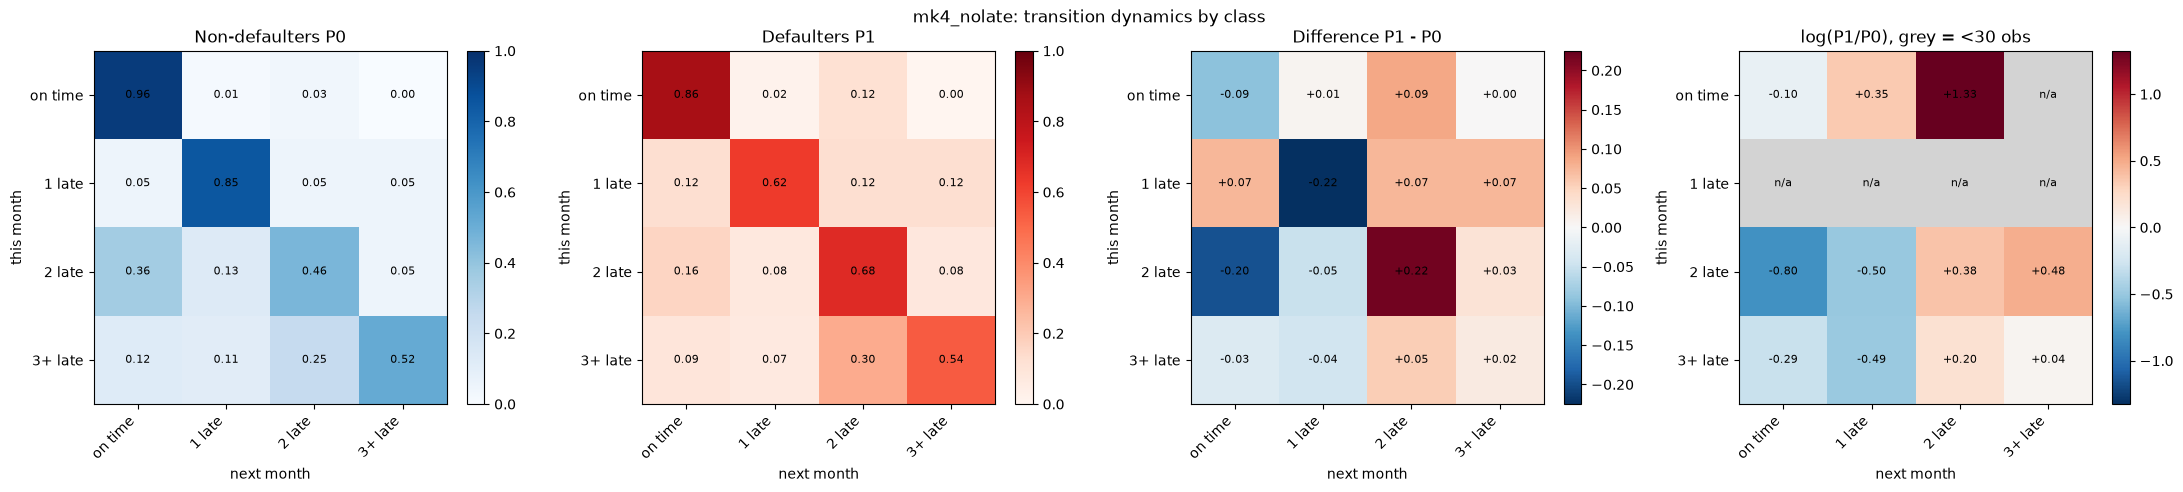

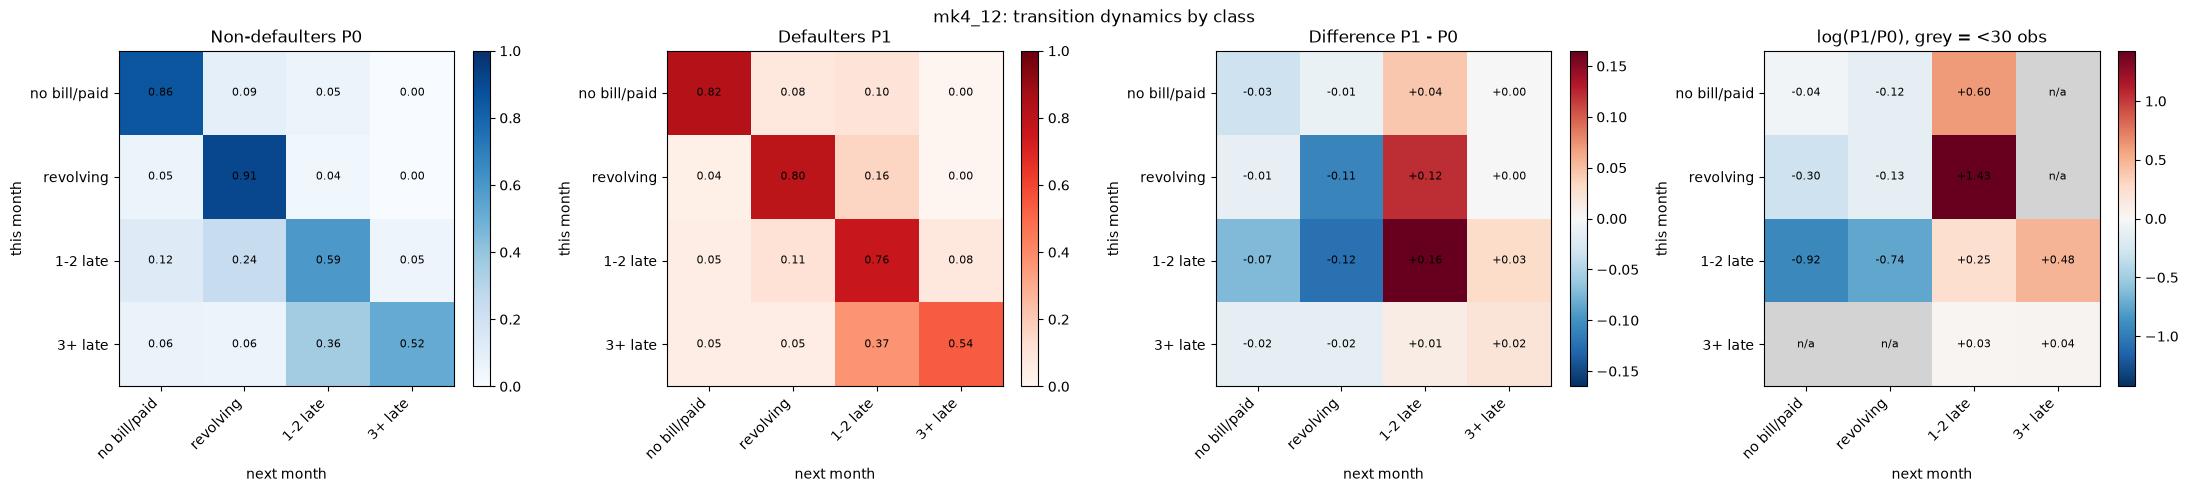

In [12]:
def raw_counts(S, K):
    C = np.zeros((K, K), dtype=int)
    np.add.at(C, (S[:, :-1].ravel(), S[:, 1:].ravel()), 1)
    return C

def _prep(key, models, labels, data, pay_cols, y):
    m = models[key]; K = m["K"]
    lab = labels[key] if isinstance(labels, dict) else list(labels)
    assert len(lab) == K, f"{key}: {len(lab)} labels but K={K}"
    y = np.asarray(y)
    S = m["to_state"](data[pay_cols].values)
    C0, C1 = raw_counts(S[y == 0], K), raw_counts(S[y == 1], K)
    return m, K, lab, C0, C1

def _tick_labels(ax, lab):
    K = len(lab)
    ax.set_xticks(range(K)); ax.set_xticklabels(lab, rotation=45, ha="right")
    ax.set_yticks(range(K)); ax.set_yticklabels(lab)
    ax.set_xlabel("next month"); ax.set_ylabel("this month")


def plot_class_heatmaps(key, models, labels, data, pay_cols, y, min_n=30,
                        figsize=(22, 4.8)):
    m, K, lab, C0, C1 = _prep(key, models, labels, data, pay_cols, y)
    P0, P1 = m["P0"], m["P1"]
    low = np.minimum(C0, C1) < min_n
    diff, logr = P1 - P0, np.log(P1) - np.log(P0)
    logr_m = np.ma.array(logr, mask=low)
    cm = plt.get_cmap("RdBu_r").copy(); cm.set_bad("lightgrey")
    dl, ll = np.abs(diff).max(), np.abs(logr_m).max()

    fig, axs = plt.subplots(1, 4, figsize=figsize)
    panels = [(P0, "Non-defaulters P0", "Blues", 0, 1, ".2f"),
              (P1, "Defaulters P1", "Reds", 0, 1, ".2f"),
              (diff, "Difference P1 - P0", cm, -dl, dl, "+.2f"),
              (logr_m, f"log(P1/P0), grey = <{min_n} obs", cm, -ll, ll, "+.2f")]
    for ax, (M, t, cmap, lo, hi, fmt) in zip(axs, panels):
        im = ax.imshow(M, cmap=cmap, vmin=lo, vmax=hi); ax.set_title(t)
        for i in range(K):
            for j in range(K):
                txt = "n/a" if (M is logr_m and low[i, j]) else format(M[i, j], fmt)
                ax.text(j, i, txt, ha="center", va="center", fontsize=8)
        plt.colorbar(im, ax=ax, fraction=0.046)
        _tick_labels(ax, lab)
    fig.suptitle(f"{key}: transition dynamics by class")
    plt.tight_layout(); plt.show()
    return dict(C0=C0, C1=C1, low=low)

for k in markov_models:
    plot_class_heatmaps(k, markov_models, labels_all, train, pay_cols, y_tr)


**Interpretation of Heatmaps**

Regardless of the split the diagonals dominate. Non-defaulters are more stable in the on-time states (e.g. 0.96 on time in `mk4_nolate`), while defaulters are less stable in comparison (0.86 in `mk4_nolate`). Defaulters are also more persistent in late states (e.g. 0.68 vs 0.46 for "2 late" in `mk4_nolate`). A caveat to this is that non-defaulters seem to be more stable in the 1-month-late state (0.81 vs 0.56 in `mk5_full`); however, this is explained below.

The log-ratio panels show that the model's score is driven mainly by two kinds of transition. Moving from a not-late state into a late state is strong evidence of default (log ratios of +0.8 to +1.4 into "2+ late" in `mk5_full`), whereas leaving a late state for a non-late one is evidence against it (−0.5 to −0.9). Staying in the most delinquent state is only weakly informative about the class (log ratios of +0.04 for "3+ late" in `mk4_12` and `mk4_nolate`), so being in "3+ late" says little about the class by itself.

The "1 late" row in `mk5_full` and `mk4_nolate` is greyed out because it is based on fewer than 30 transitions. Its off-diagonal entries are all identical within each class (0.05 for non-defaulters and 0.11 to 0.12 for defaulters), which is what Laplace smoothing produces when counts are near zero. The apparent result that non-defaulters stay "1 late" more often than defaulters (0.85 vs 0.62 in `mk4_nolate`, 0.81 vs 0.56 in `mk5_full`) is therefore a smoothing artefact, not real behaviour. In `mk4_12`, merging "1 late" and "2 late" removes this problem: the merged row is well supported and gives the expected pattern, with defaulters staying late (0.76 vs 0.59) and non-defaulters recovering more often.

The chains pick up plausible class-specific behaviour, and the main signal comes from entering and leaving delinquency. The sparse "1 late" state is the main weakness of the finer splits, which is why we will compare them with merged versions in the next section.



### 5.6.4 Count Heatmaps

The probabilities in the heatmaps are estimated from counts of month-to-month transitions, so each estimate is only as reliable as the number of observations behind it. The figure below shows these counts for the 5-state split `mk5_full`: the raw transition counts for non-defaulters and defaulters (on a log colour scale, with cells below 30 observations in bold), and the total number of transitions out of each state for each class. The training set has 17,997 customers, giving 89,985 transitions.

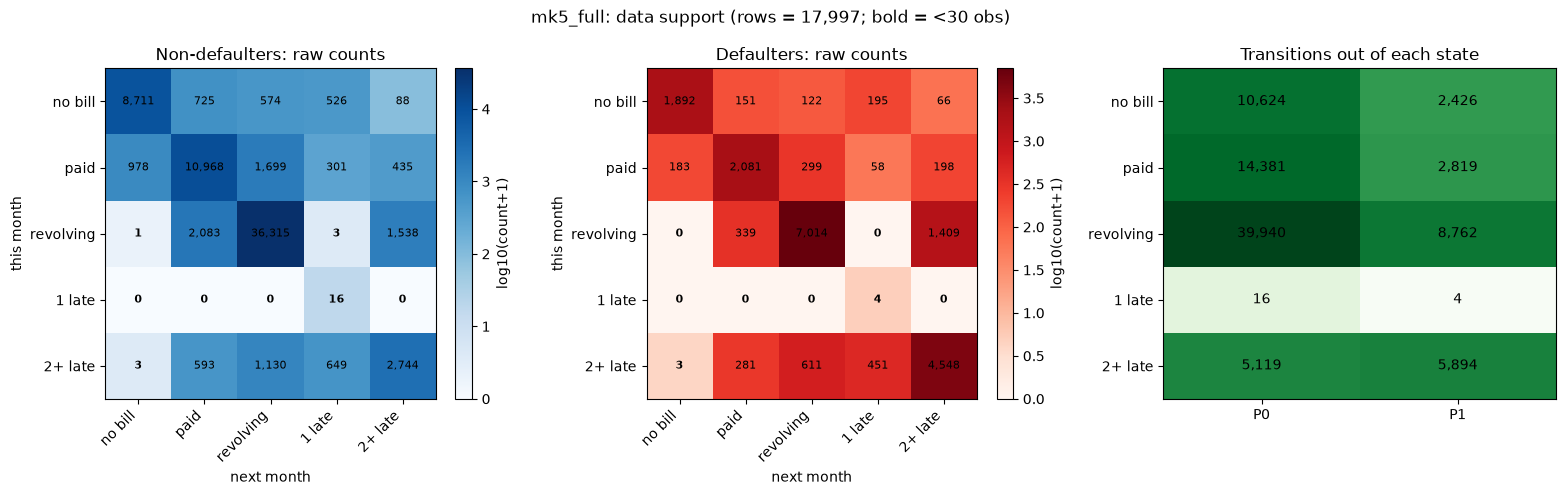

In [13]:
MIN_N = 30  # cells with fewer raw transitions than this are flagged as unreliable

def plot_count_heatmaps(key, models, labels, data, pay_cols, y, min_n=30,
                        figsize=(16, 4.8)):
    m, K, lab, C0, C1 = _prep(key, models, labels, data, pay_cols, y)

    fig, axs = plt.subplots(1, 3, figsize=figsize)
    for ax, C, t, cmap in [(axs[0], C0, "Non-defaulters: raw counts", "Blues"),
                           (axs[1], C1, "Defaulters: raw counts", "Reds")]:
        im = ax.imshow(np.log10(C + 1), cmap=cmap); ax.set_title(t)
        for i in range(K):
            for j in range(K):
                ax.text(j, i, f"{C[i, j]:,}", ha="center", va="center", fontsize=8,
                        fontweight="bold" if C[i, j] < min_n else "normal")
        plt.colorbar(im, ax=ax, fraction=0.046).set_label("log10(count+1)")
        _tick_labels(ax, lab)

    row_n = np.vstack([C0.sum(1), C1.sum(1)]).T
    axs[2].imshow(np.log10(row_n + 1), cmap="Greens", aspect="auto")
    for i in range(K):
        for c in range(2):
            axs[2].text(c, i, f"{row_n[i, c]:,}", ha="center", va="center")
    axs[2].set_xticks([0, 1]); axs[2].set_xticklabels(["P0", "P1"])
    axs[2].set_yticks(range(K)); axs[2].set_yticklabels(lab)
    axs[2].set_title("Transitions out of each state")

    fig.suptitle(f"{key}: data support (rows = {len(data):,}; bold = <{min_n} obs)")
    plt.tight_layout(); plt.show()
    return dict(C0=C0, C1=C1)


plot_count_heatmaps("mk5_full", markov_models, labels_all, train, pay_cols, y_tr);

**Findings**
- Most states are well supported. Every state other than "1 late" has at least 2,400 transitions out of it for each class.
- As defaulters have fewer observations overall (19,905 transitions against 70,080), their estimates are less precise than the non-defaulters', although still adequate to use.
- The "1 late" state is the exception: there are only 16 transitions for non-defaulters and 4 for defaulters. Every transition out of it is therefore dominated by Laplace smoothing; this explains the non-defaulters' apparent stability in the 1-month-late state. It is simply an artefact of the lack of data in those rows being dominated by Laplace smoothing rather than a meaningful behavioural difference.
- A few other cells are very sparse (below 30), for example revolving to "1 late" (3 and 0) and "2+ late" to "no bill" (3 and 3). These are transitions that rarely or never happen, rather than a lack of data in the starting state.
- "1 late" is entered far more often than it is left (about 2,200 transitions into it, against 20 out of it), so it behaves mostly as a one-off state at the end of a customer's sequence.

We will keep `mk5_full` in the comparison as the finest split, but interpret its "1 late" row with caution because it reflects the smoothing prior rather than observed behaviour. Because so few transitions involve this state, its effect on predictions is small, but the sparse row remains the main weakness of the finer splits. This motivates comparing merged splits in the next section.

### 5.6.5 Comparison

In this section, we compare the baseline pooled chain with the three two-class splits we kept (`mk5_full`, `mk4_nolate`, `mk4_12`). We want to answer two questions: 
- Is the two-class chain a clear improvement over the baseline?  
- Which state split should be carried forward?

State splits were screened on the validation set.

We use several metrics because each measures something different:
- **AUC** measures how well a model ranks defaulters above non-defaulters. It is unaffected by how well the probabilities are calibrated.
- **Log loss and Brier score** measure the quality of the predicted probabilities, so they penalise a model whose probabilities are wrong even if its ranking is good.
- **Calibration and cumulative-gains curves** show where probabilities are too high or too low, and how many defaulters are captured by targeting the highest-risk customers.
- **Confusion matrices** show errors at a fixed threshold. The same cut-off of 0.2 is applied to every model, so the matrices describe one common operating point rather than a tuned one. Models whose probabilities are more or less cautious flag a different share of customers at the same cut-off, so we use them to illustrate behaviour and not to rank models.

Two points affect how fair the comparison is. The two-class models are Platt-scaled on the validation set while the baseline is not, so some of their advantage in log loss, Brier score, and calibration may come from calibration alone; but AUC won't be affected by this. Their log loss and Brier scores are also slightly optimistic, as the Platt scaling is fitted and scored on the same validation customers. Differences between splits are also small, so we judge them against the scale of sampling variability (the bootstrap intervals for AUC differences in Section 5.7.2 are about ±0.01) and not point estimates alone.

For an improvement to be clear it must hold across the metrics and exceed this variability. If the splits are indistinguishable, we choose the one with the fewest states and the best data support per transition.


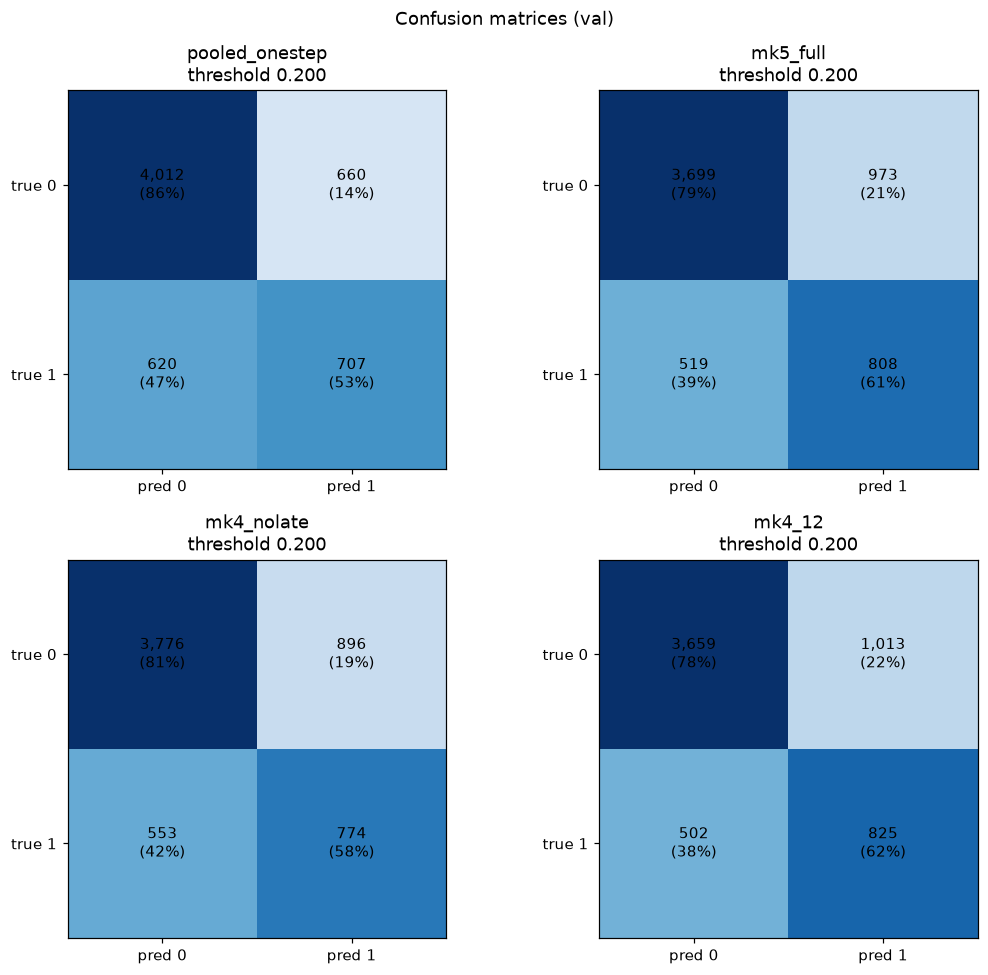
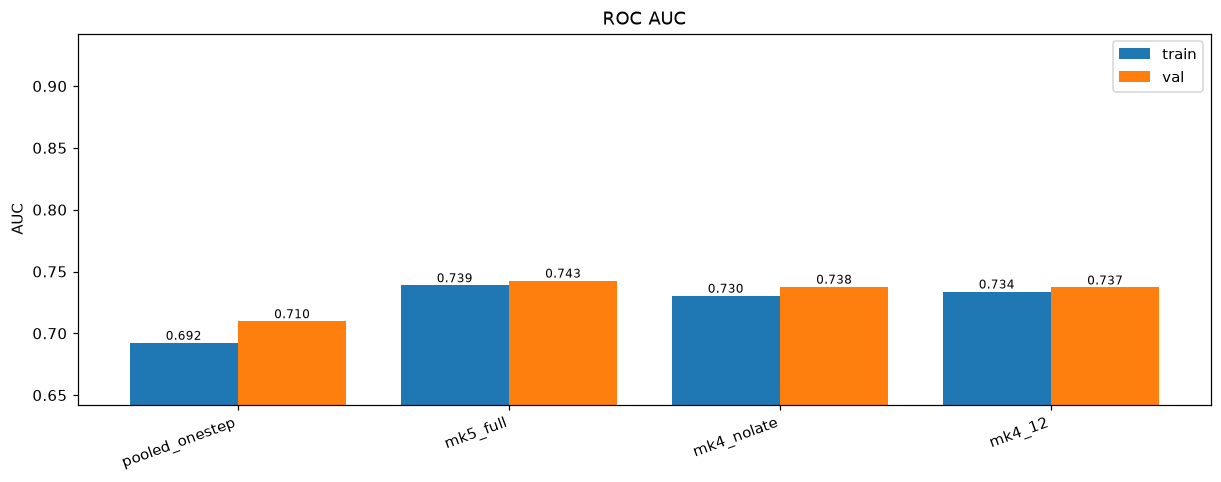
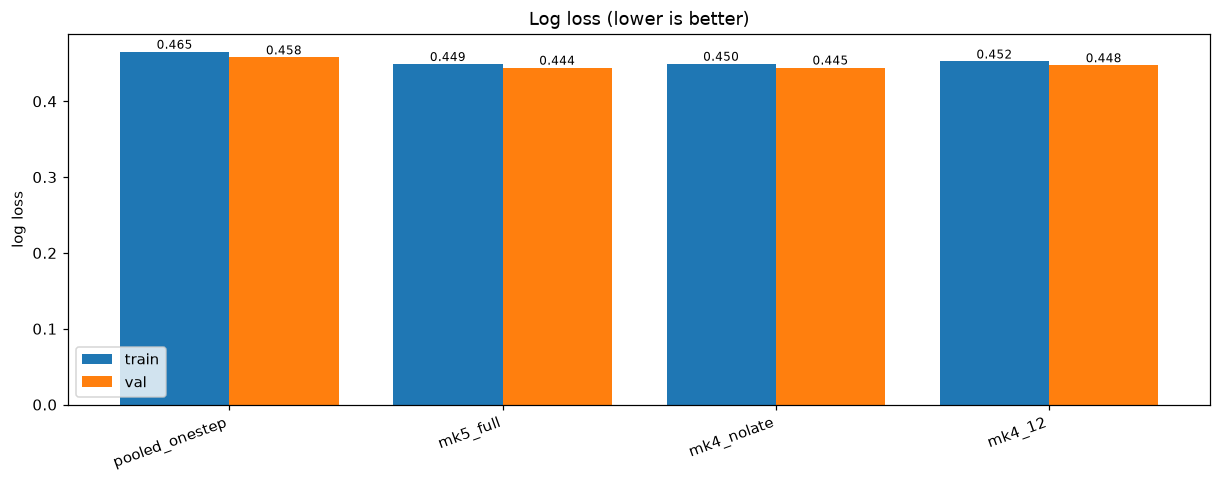
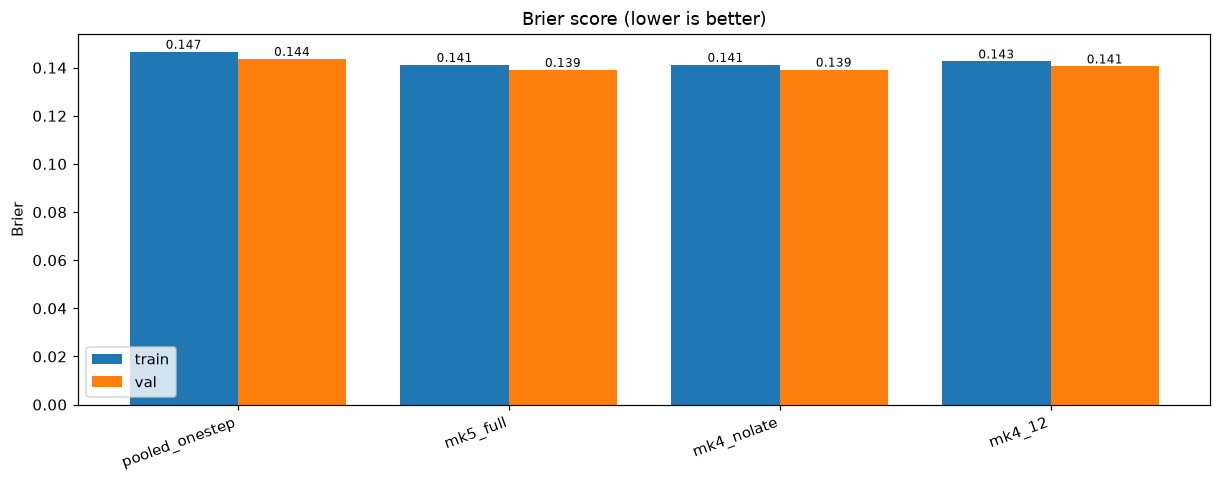


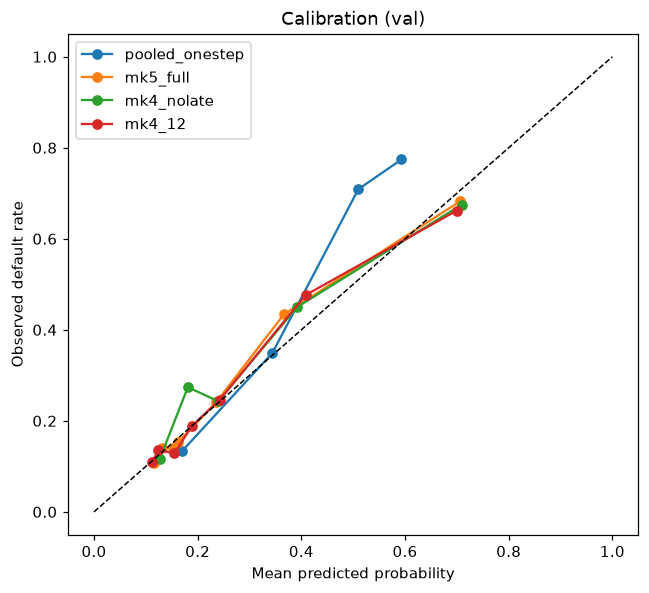
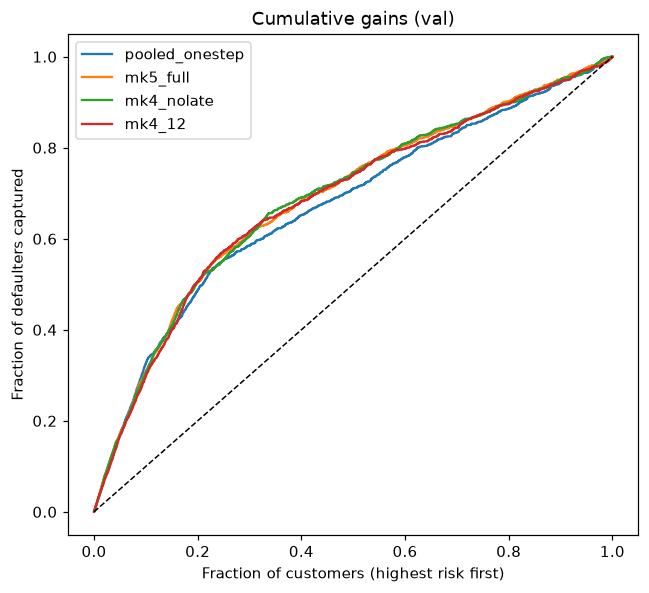
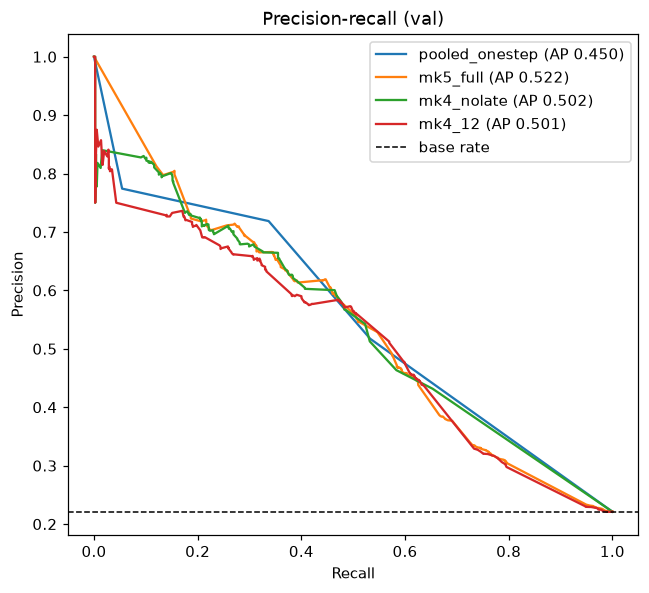
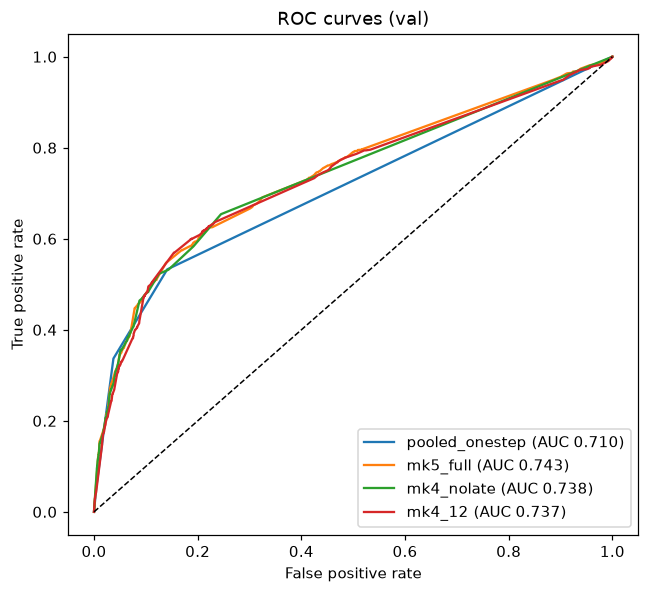

In [14]:
compare = {"pooled_onestep": pooled, "mk5_full": markov_models["mk5_full"], "mk4_nolate": markov_models["mk4_nolate"], "mk4_12": markov_models["mk4_12"]}
show_row(
    lambda: plot_confusion(compare, split="val",thresholds={"pooled_onestep": 0.2, "mk5_full": 0.2, "mk4_nolate": 0.2, "mk4_12": 0.2}),
    lambda: plot_auc(compare),
    lambda: plot_logloss(compare),
    lambda: plot_brier(compare),

    width=800
)

show_row(
    lambda: plot_calibration(compare, split="val"),
    lambda: plot_gains(compare),
    lambda: plot_pr(compare),
    lambda: plot_roc(compare),
    width=500
)

**Interpretation**

Training and validation scores are very close for every model, and validation AUC is slightly above training AUC. This suggests the models are not overfitting, so the validation comparison is reliable. The cumulative gains curves also show the two-class Markov models capturing defaulters faster than the pooled model when customers are ranked from highest risk to lowest, beyond roughly the highest-risk fifth of customers. The two-class models all look well calibrated compared to the pooled chain with its miscalibration at extremes.

Based on the metrics above, the `mk5_full` model leads the models on the validation data slightly, even considering the sparsity of the "1 late" row, perhaps because the state is rare so does not disrupt classifications much. The pooled one-step model is clearly the weakest, while the `mk4` models perform very similarly to each other. The `mk5_full` model has the highest discrimination and the best probability accuracy. At the shared 0.2 cut-off the splits mainly differ in where they sit on the same trade-off (recall 61%, 58% and 62% for `mk5_full`, `mk4_nolate` and `mk4_12`, with specificity 79%, 81% and 78%). The margin over the 4-state variants is modest, but it is consistent across every metric. Its advantage over the coarser splits (about 0.005 AUC) is smaller than the bootstrap intervals in Section 5.7.2, though, so it may be noise, and it depends on a sparse "1 late" row (Section 5.6.4). Debt bins will multiply the number of states in the next section, so we build on a coarser three-state split (`mk3`) and on `mk4_12`, which give up almost nothing in accuracy and keep every row supported by data.

## 5.7 Supplementary Data

### 5.7.1 Method

The goal of this next section is to investigate whether the two-class chain can be further improved by utilising supplementary data to distinguish new chain states. We will use how much customers owe alongside their payment status in order to better distinguish the exact patterns of defaulters compared to non-defaulters. 

Each month's state combines the payment state $s_{i,t}$ and the debt bin $b_{i,t}$:

$$
x_{i,t} = (s_{i,t},\, b_{i,t}), \qquad K = K_{\text{pay}} \times B
$$

For an initial test of this model, we will use a smaller `mk3` model (to limit the state-space size) and compare possible design choices we can make about this model. For the 3-state payment split (current/paid, revolving, late) with 3 debt bins, this gives $K = 9$ states and 81 transition cells per class. The model is otherwise unchanged: one chain is fitted per class with Laplace smoothing, customers are scored by the log-likelihood ratio of their sequence plus the class prior, and the score is calibrated with Platt scaling on the validation set.

The chain can now learn two new things that payment status alone cannot show:

- whether the same payment state means different risk at different debt levels (for example, a late customer with a large balance versus a small one), and
- whether the way debt moves from month to month differs between defaulters and non-defaulters (for example, debt growing while the customer stays revolving).

In [15]:

def debt_matrix(d, measure="util"):
    bill = np.clip(d[bill_cols].values.astype(float), 0, None)       # chronological Apr..Sep
    return bill / d["LIMIT_BAL"].values[:, None] if measure == "util" else bill

def fit_chain_aug(S, K, alpha=1.0):
    init = np.bincount(S[:, 0], minlength=K) + alpha
    C = np.full((K, K), alpha)
    np.add.at(C, (S[:, :-1].ravel(), S[:, 1:].ravel()), 1)
    return init / init.sum(), C / C.sum(1, keepdims=True)

def llr_aug(S, m):
    sc = np.log(m["init1"][S[:, 0]]) - np.log(m["init0"][S[:, 0]])
    for t in range(S.shape[1] - 1):
        sc += np.log(m["P1"][S[:, t], S[:, t+1]]) - np.log(m["P0"][S[:, t], S[:, t+1]])
    return sc + m["log_prior"]

def build_markov_debt(name, base_to_state, K_base, base_labels=None, n_bins=3,
                      measure="util", split=None, alpha=1.0):
    # debt-bin edges from TRAIN only
    D_tr = debt_matrix(train, measure)
    edges = np.unique(np.quantile(D_tr.ravel(), np.linspace(0, 1, n_bins + 1)[1:-1]))
    nb = len(edges) + 1
    split = set(range(K_base) if split is None else split)   # base states to subdivide by debt

    lookup, labels, k = np.zeros((K_base, nb), dtype=int), [], 0
    for s in range(K_base):
        base = base_labels[s] if base_labels else str(s)
        if s in split:
            for b in range(nb):
                lookup[s, b] = k; k += 1; labels.append(f"{base} | debt {b+1}/{nb}")
        else:
            lookup[s, :] = k; k += 1; labels.append(base)
    K = k

    def encode(d):
        s = base_to_state(d[pay_cols].values)
        return lookup[s, np.digitize(debt_matrix(d, measure), edges)]

    S_tr, S_va, S_te = encode(train), encode(validation), encode(test)
    ytr = np.asarray(y_tr).astype(int)
    init0, P0 = fit_chain_aug(S_tr[ytr == 0], K, alpha)       # TRAIN only
    init1, P1 = fit_chain_aug(S_tr[ytr == 1], K, alpha)
    m = dict(name=name, K=K, labels=labels, edges=edges, init0=init0, P0=P0, init1=init1, P1=P1,
             log_prior=np.log(ytr.mean() / (1 - ytr.mean())))
    m["S_tr"], m["y_tr"] = S_tr, y_tr
    m["sc_tr"], m["sc_va"], m["sc_te"] = llr_aug(S_tr, m), llr_aug(S_va, m), llr_aug(S_te, m)
    m["platt"] = LogisticRegression(C=1e6).fit(m["sc_va"].reshape(-1, 1), y_va)   # VALIDATION only
    return m



### 5.7.2 Data Selection

Debt can be measured by using credit utilisation instead of raw bill amount, where negative bills are clipped to zero. This allows customers with different credit limits to be compared with one another on a relative scale instead of just using the raw bill value. Statuses are then separated by the percentage of the credit limit accessed. For three bins, the data is split into thirds (terciles):
$$
u_{i,t} = \frac{\max(\text{BILL\_AMT}_{i,t},\, 0)}{\text{LIMIT\_BAL}_i}
$$

**Correlation**

Before we decide on this as our metric, we want to check that it is the better option, as we do not want to risk losing performance. We will first test how differently the two options segment the training data by calculating the Spearman rank correlation. We use Spearman's rank correlation because the bins are defined by quantiles (so only the ordering of values matters), alongside a cross-tabulation of the three-bin splits that the model would actually use.

In [16]:
b_tr = debt_matrix(train, "bill").ravel()
u_tr = debt_matrix(train, "util").ravel()
print("Spearman correlation:", spearmanr(b_tr, u_tr)[0])

def terciles(x): return np.digitize(x, np.quantile(x, [1/3, 2/3]))
print(pd.crosstab(terciles(b_tr), terciles(u_tr), normalize="index").round(2))

Spearman correlation: 0.8379257483447687
col_0     0     1     2
row_0                  
0      0.91  0.09  0.00
1      0.09  0.58  0.32
2      0.00  0.33  0.67


The Spearman correlation of 0.838 is reasonably high, so both measures carry largely the same information and there is little reason to expect a gain from including both. The table shows where the mismatches are occurring: about 72% of observations fall in the same bin, and almost no observations move by more than one bin (both corner cells round to 0.00). Agreement is highest in the lowest bin (91%) and lowest in the middle bin (58%), where a medium bill can become a high or low utilisation depending on the credit limit. We therefore expect the two choices to perform similarly. In that case, credit utilisation is still justified, as it is more interpretable for clients with varying credit limits.



**Paired Bootstrap**

Similar bins do not guarantee similar performance, so we test it directly. We use a debt-free `mk3` two-class chain as the control and build debt models for each measure (raw bill and utilisation) with 2, 3, and 4 bins. For each pair of models, we resample the validation customers with replacement 1,000 times and compute the difference in AUC on each resample. Using the same resampled customers for both models makes the comparison paired, which gives a tighter confidence interval than comparing the two models separately. We report the 95% confidence interval of the difference. AUC is computed on the raw scores, so the comparison does not depend on calibration.

In [17]:
# --- 1. add mk3 and rebuild the state dictionary ---
STATE_SPECS["mk3"] = dict(
    map={-2: 0, -1: 0, 0: 1},                        # current/paid, revolving
    top=1,                                            # every status >= 1 month late -> one state
    labels=["current/paid", "revolving", "late (1+)"],
)
states = make_all_states(STATE_SPECS)
base = states["mk3"]
assert base["K"] == 3, base["labels"]
print(base["K"], base["labels"], np.bincount(base["to_state"](train[pay_cols].values).ravel()))

# --- 2. fast bootstrap helpers ---
def make_boot_idx(n, B=1000, seed=0):
    return np.random.default_rng(seed).integers(0, n, (B, n))        # same resamples for every model

def boot_auc(y, s, idx):
    yb, r = y[idx], rankdata(np.asarray(s)[idx], axis=1)             # ranks handle ties correctly
    npos = yb.sum(1); nneg = idx.shape[1] - npos
    return ((r * yb).sum(1) - npos * (npos + 1) / 2) / (npos * nneg)  # Mann-Whitney AUC per resample

def diff_ci(a, b):
    d = a - b
    return d.mean(), tuple(np.percentile(d, [2.5, 97.5]))

# --- 3. build models once, bootstrap each once ---
y_va_a = np.asarray(y_va)
idx = make_boot_idx(len(y_va_a))
control = build_markov("mk3", base["to_state"], base["K"])           # no debt
boot = {"mk3": boot_auc(y_va_a, control["sc_va"], idx)}               # control computed once

models, rows = {}, []
for measure in ("util", "bill"):
    for nb in (2, 3, 4):
        name = f"mk3_{measure}{nb}"
        m = models[name] = build_markov_debt(name, base["to_state"], base["K"],
                                             base_labels=base["labels"], n_bins=nb, measure=measure)
        boot[name] = boot_auc(y_va_a, m["sc_va"], idx)
        diff, (lo, hi) = diff_ci(boot[name], boot["mk3"])
        rows.append(dict(measure=measure, bins=nb, K=m["K"], val_AUC=roc_auc_score(y_va_a, m["sc_va"]),
                         AUC_gain_vs_nodebt=diff, CI_low=lo, CI_high=hi))
results = pd.DataFrame(rows).round(4)
results

3 ['current/paid', 'revolving', 'late (1+)'] [35357 57536 15089]


,measure,bins,K,val_AUC,AUC_gain_vs_nodebt,CI_low,CI_high
0,util,2,6,0.7479,0.0108,0.0047,0.0171
1,util,3,9,0.7619,0.0247,0.0159,0.0342
2,util,4,12,0.7628,0.0256,0.0146,0.0366
3,bill,2,6,0.7512,0.0140,0.0060,0.0220
4,bill,3,9,0.7590,0.0220,0.0122,0.0317
5,bill,4,12,0.7549,0.0178,0.0068,0.0279


**Comparison**

What is immediately encouraging to see is that the debt data improves all models, as the lower bounds of the 95% confidence intervals are all positive. For the difference between utilisation (`util`) and raw bill (`bill`), however, there is no clear leader from this data. This at least means that it is unlikely that using credit utilisation is significantly limiting the model, so we will proceed with it on the grounds of interpretability. Looking at the number of bins, three bins give a larger AUC gain than two (about 0.025 compared with 0.011 for utilisation, although the intervals overlap slightly so this was not tested directly), and a fourth bin adds almost nothing; therefore, to balance sparsity and model size, we will select three bins as standard.


### 5.7.3 Model Creation

A 5-state base model would produce many more composite states, meaning many more transition probabilities to estimate. A large number of these cells would contain very few observations, so the estimated probabilities would be unstable and have high variance. This sparsity risks overfitting and weakens the validity of the extended model. The performance gap between the 5-state and 4-state models is small (about 0.006 in AUC between `mk5_full` and `mk4_12`, and 0.021 in AP). The loss in predictive performance is therefore small compared with the gain in estimation stability. Following directly from the previous development, alongside our `mk3_debt` model we will develop two versions of the `mk4_12` model—one using two debt bins and the other using three—to compare gains across differently sized transition matrices.

| Model | Payment states | Debt bins | States $K$ | Transition cells per class |
|---|---|---|---|---|
| `mk3` (control) | current/paid, revolving, late | none | 3 | 9 |
| `mk3_debt` | current/paid, revolving, late | 3 | 9 | 81 |
| `mk4_12_debt` | no bill/paid, revolving, 1-2 late, 3+ late | 3 | 12 | 144 |
| `mk4_12_debt_2` | no bill/paid, revolving, 1-2 late, 3+ late | 2 | 8 | 64 |

In [18]:
# blank model: the same 3 payment states, no debt
mk3 = build_markov("mk3", base["to_state"], base["K"])

# debt model: 3 payment states x 3 debt bins = 9 states
mk3_debt = build_markov_debt("mk3_debt", base["to_state"], base["K"],
                             base_labels=base["labels"], n_bins=3, measure="util")

# 4 payment states x 3 debt bins = 12 states
mk4_12_debt = build_markov_debt("mk4_12_debt", states["mk4_12"]["to_state"], states["mk4_12"]["K"],
                                base_labels=states["mk4_12"]["labels"], n_bins=3)

# 4 payment states x 2 debt bins = 8 states
mk4_12_debt_2 = build_markov_debt("mk4_12_debt_2", states["mk4_12"]["to_state"], states["mk4_12"]["K"],
                                  base_labels=states["mk4_12"]["labels"], n_bins=2, measure="util")

debt_models = {"mk3_debt": mk3_debt, "mk4_12_debt": mk4_12_debt, "mk4_12_debt_2": mk4_12_debt_2}

### 5.7.4 Heatmaps

**Cost.** Multiplying the number of states by $B$ multiplies the number of transition cells by $B^2$, so each cell is estimated from fewer transitions. Because of the larger number of cells, it is more likely that there will be low-count cells. Cells with fewer than 30 observations in either class are greyed out in the heatmaps, and their probabilities are dominated by smoothing.
 
We therefore keep the number of states small and, in Section 5.7.5, compare each debt model against the same payment split without debt to check that the added information outweighs the added sparsity.

**Sensitivity.** The choice of debt measure (utilisation or raw bill) and the number of bins ($B=2,3,4$) was tested in Section 5.7.2 using validation AUC. The code can also subdivide only some payment states by debt (the `split` argument), but that option was not explored: every payment state is subdivided here.

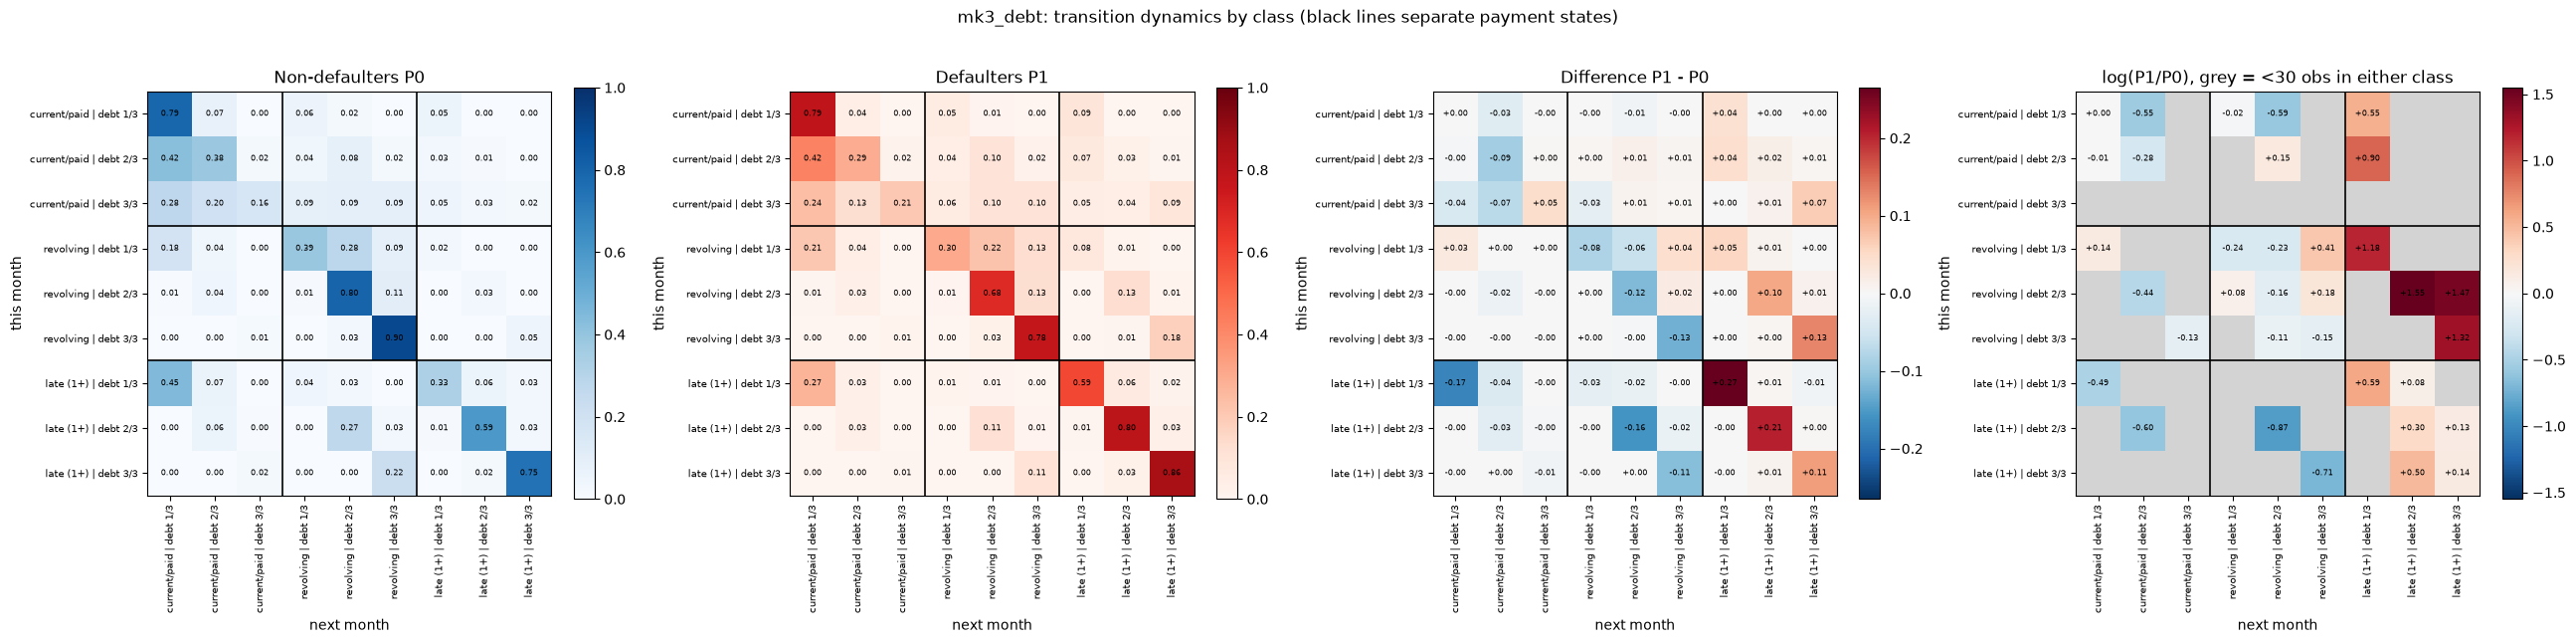

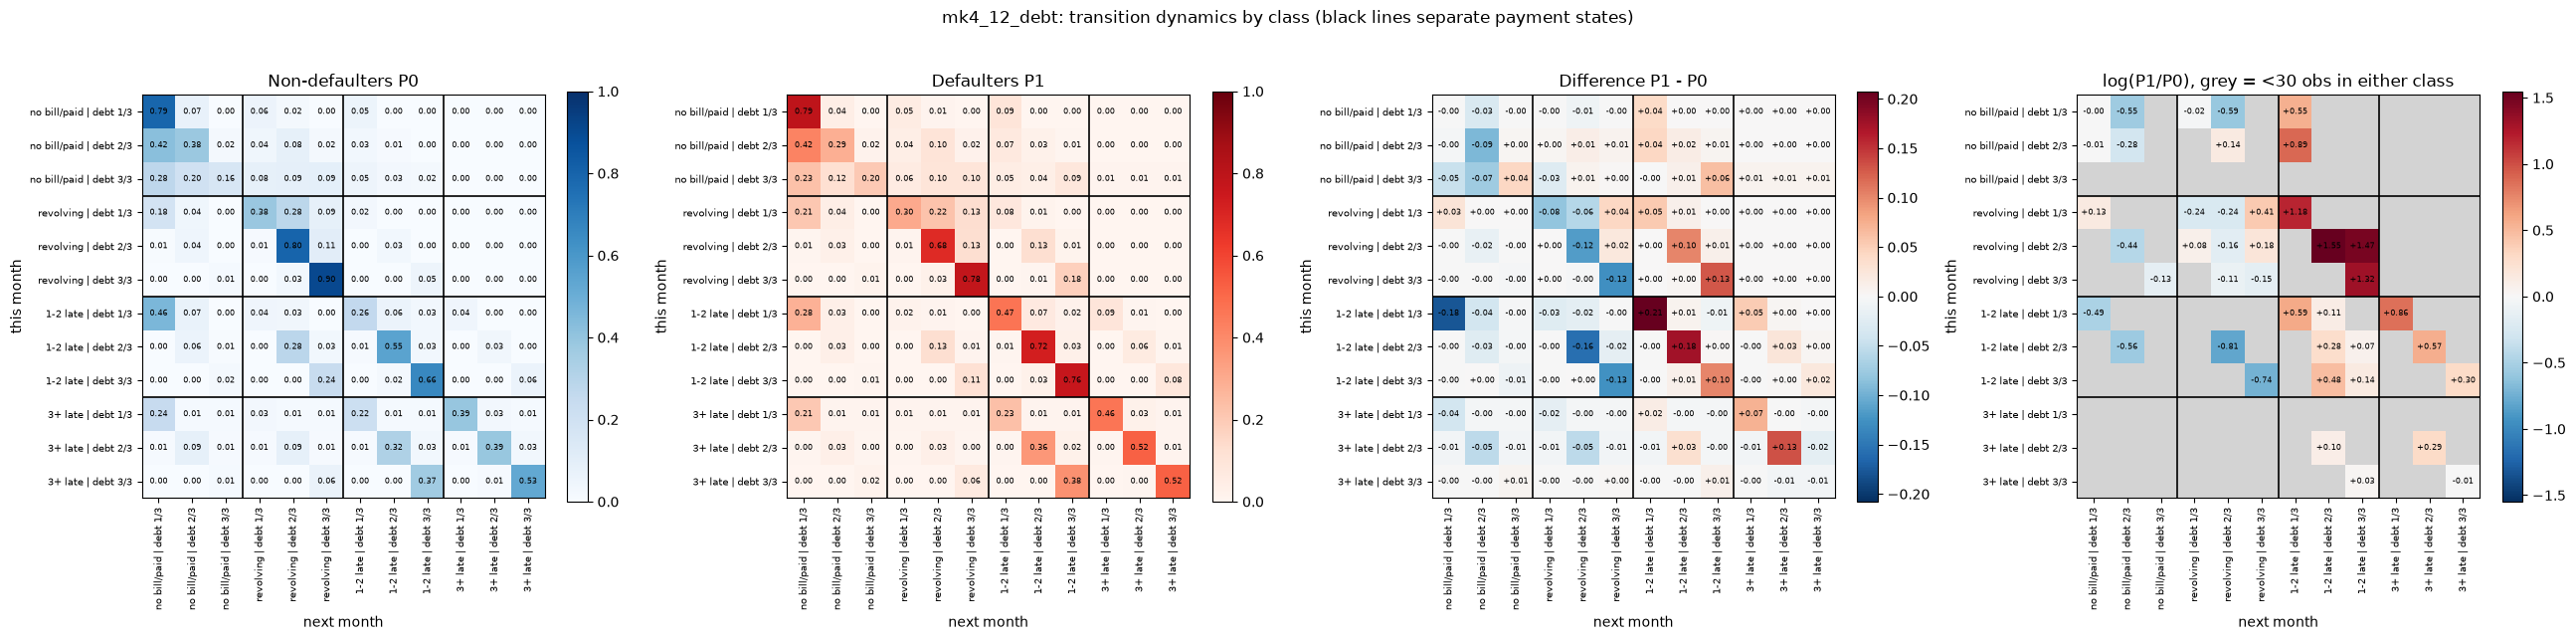

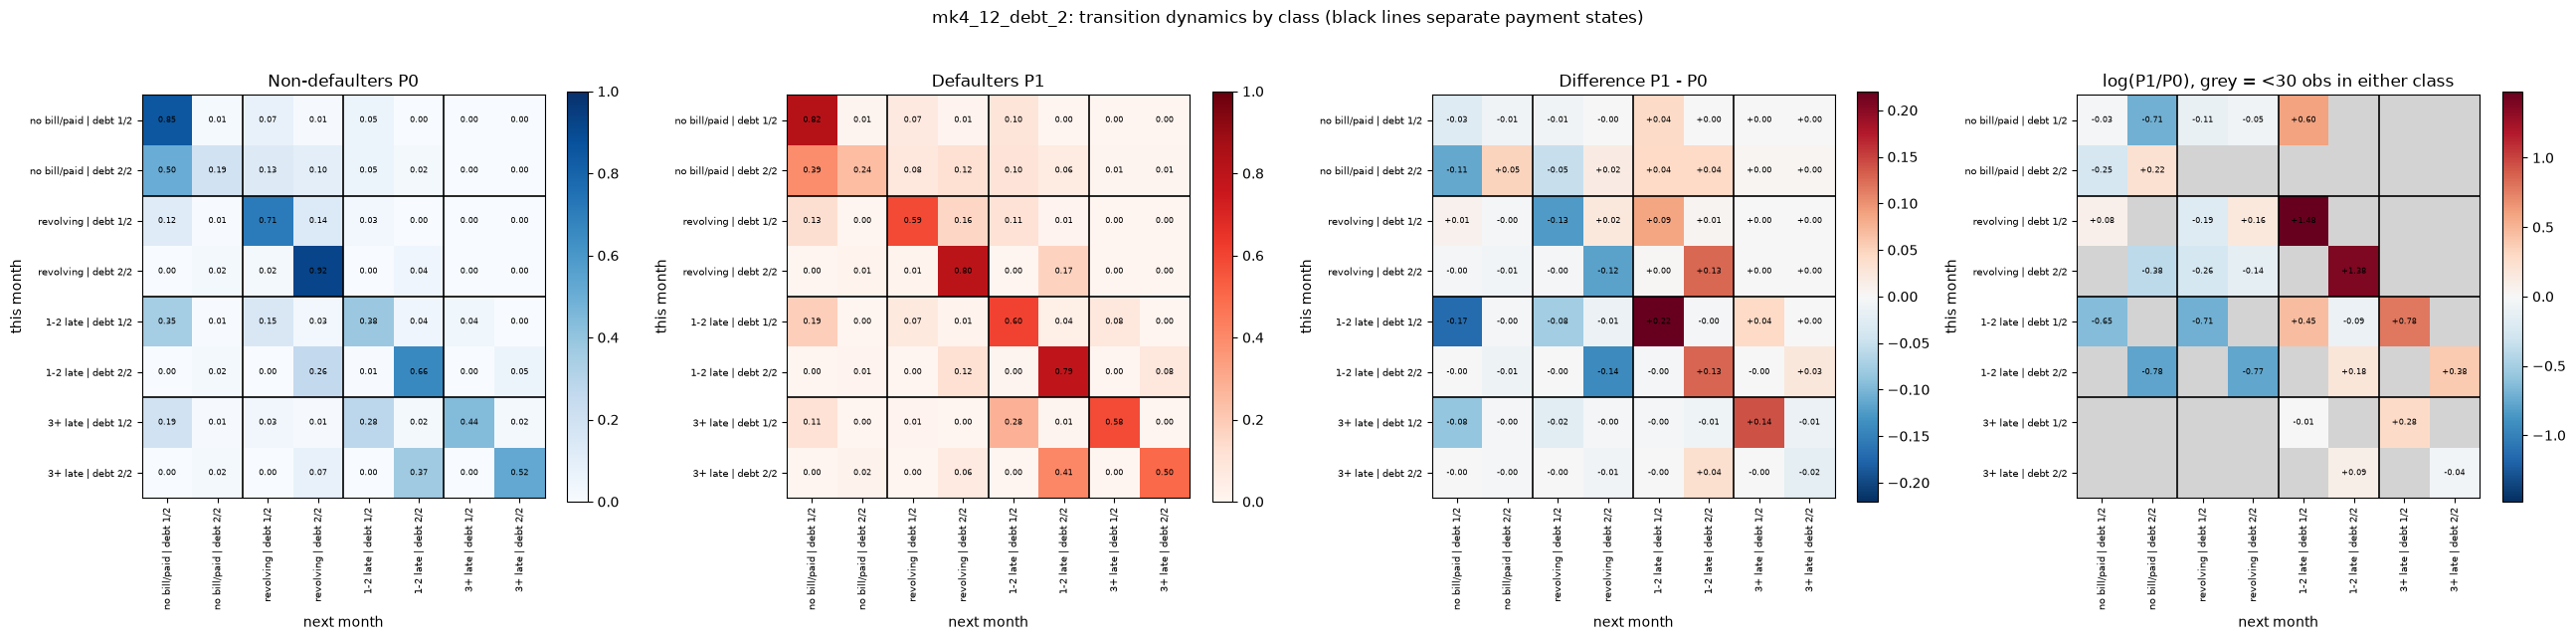

In [19]:
def plot_debt_heatmaps(m, minn=30, figsize=(26, 6.5), fs=6):
    K, lab = m["K"], list(m["labels"])
    S, y = m["S_tr"], np.asarray(m["y_tr"])
    C0, C1 = raw_counts(S[y == 0], K), raw_counts(S[y == 1], K)
    P0, P1 = m["P0"], m["P1"]
    low = np.minimum(C0, C1) < minn                         # unreliable cells
    diff = P1 - P0
    logr = np.ma.array(np.log(P1) - np.log(P0), mask=low)
    cm = plt.get_cmap("RdBu_r").copy(); cm.set_bad("lightgrey")
    dl, ll = np.abs(diff).max(), np.abs(logr).max()

    base = [l.split(" | ")[0] for l in lab]                 # group by payment state
    cuts = [i - 0.5 for i in range(1, K) if base[i] != base[i - 1]]

    panels = [("Non-defaulters P0", P0, "Blues", 0, 1),
              ("Defaulters P1", P1, "Reds", 0, 1),
              ("Difference P1 - P0", diff, cm, -dl, dl),
              (f"log(P1/P0), grey = <{minn} obs in either class", logr, cm, -ll, ll)]
    fig, axs = plt.subplots(1, 4, figsize=figsize)
    for ax, (t, M, cmap, lo, hi) in zip(axs, panels):
        im = ax.imshow(M, cmap=cmap, vmin=lo, vmax=hi)
        ax.set_title(t)
        for i in range(K):
            for j in range(K):
                masked = M is logr and low[i, j]
                txt = "" if masked else (f"{M[i, j]:.2f}" if t.startswith(("Non", "Def")) else f"{M[i, j]:+.2f}")
                ax.text(j, i, txt, ha="center", va="center", fontsize=fs)
        for c in cuts:                                       # black lines between payment states
            ax.axhline(c, color="k", lw=1.2); ax.axvline(c, color="k", lw=1.2)
        ax.set_xticks(range(K)); ax.set_xticklabels(lab, rotation=90, fontsize=7)
        ax.set_yticks(range(K)); ax.set_yticklabels(lab, fontsize=7)
        ax.set_xlabel("next month"); ax.set_ylabel("this month")
        plt.colorbar(im, ax=ax, fraction=0.046)
    fig.suptitle(f"{m['name']}: transition dynamics by class (black lines separate payment states)")
    plt.tight_layout(); plt.show()

for k in debt_models:
    plot_debt_heatmaps(debt_models[k])


**Interpretation**

Across the debt-augmented heatmaps, subdividing the payment states by credit utilisation reveals clear differences within the same delinquency level: customers in higher utilisation bins are more likely to persist in or transition into late states under $P_1$ than under $P_0$, while low-utilisation customers recover to on-time states more frequently. However, moving from `mk3_debt` (9 states) to `mk4_12_debt` (12 states) noticeably increases the number of greyed-out low-count cells (`<30` observations), whereas `mk4_12_debt_2` (8 states) maintains stronger data support per cell. 


Splitting by credit utilisation shows differences a payment-only chain cannot see. Late defaulters are far more likely to stay late at every debt level (0.59, 0.80 and 0.86 against 0.33, 0.59 and 0.75 for non-defaulters), while non-defaulters recover more often. High utilisation alone does not separate the classes, since revolving customers in the highest bin stay there at similar rates (0.90 against 0.78). What matters more is if a high balance is followed by late payment. These patterns are consistent with the finding in Section 5.7.2 that adding debt improves the model, and they are plausible: customers who are late with a large balance are the ones least likely to recover.

### 5.7.5 Performance Testing

Finally, we will look at the performance of these models and evaluate the significance of the extra dimensions.


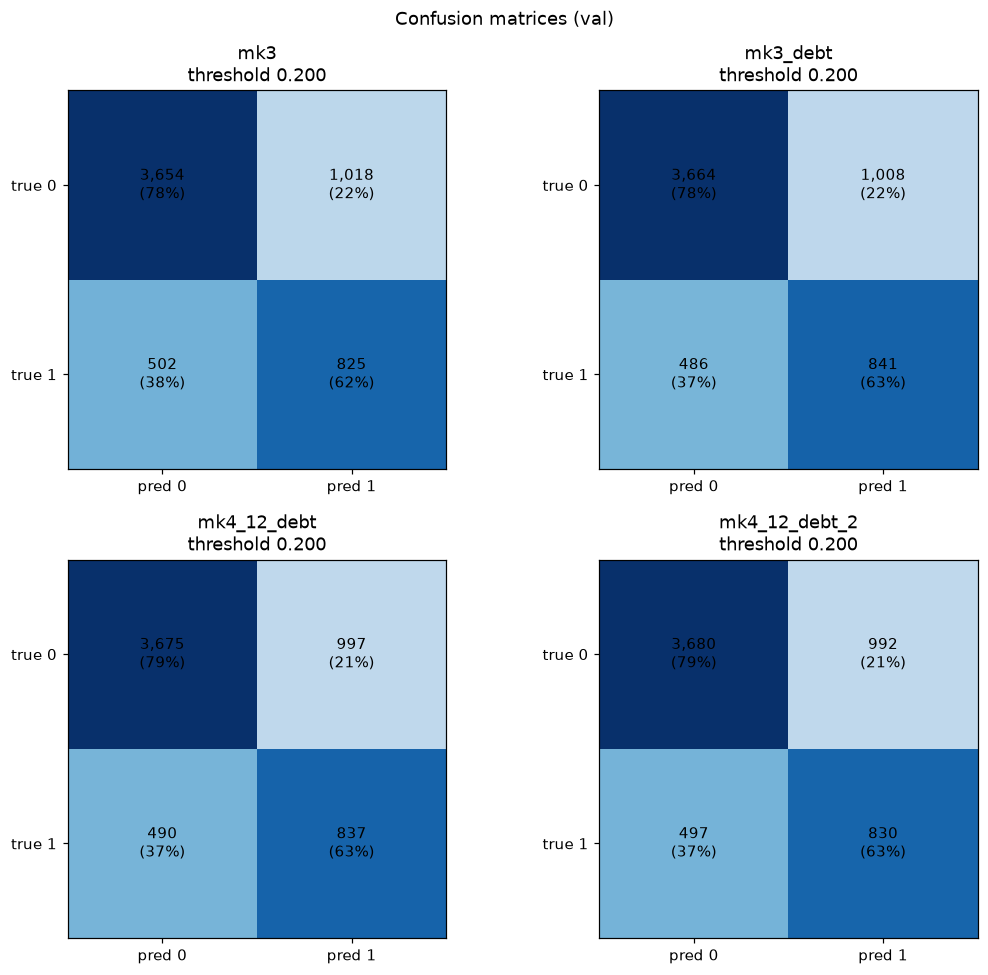
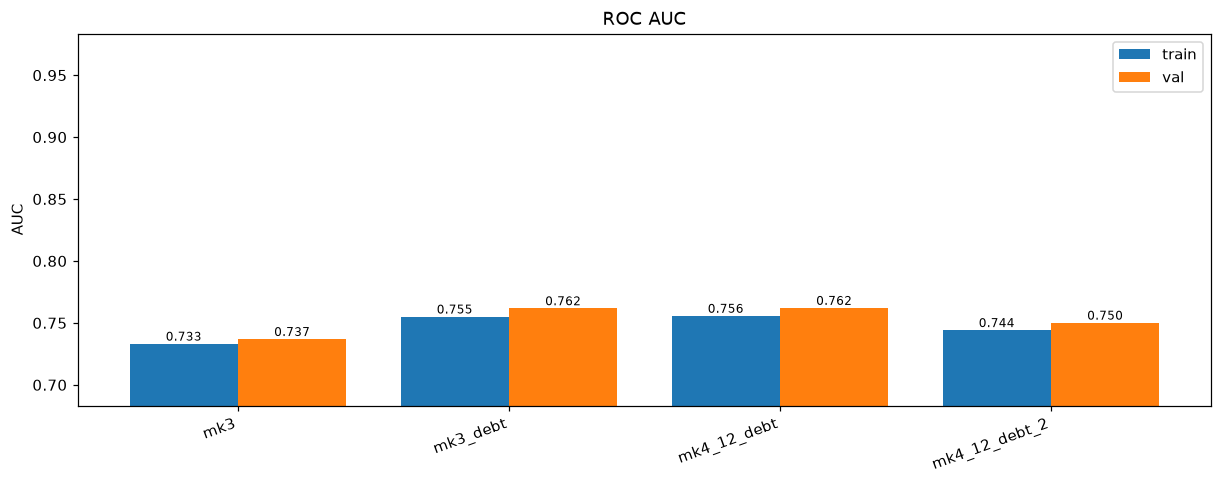
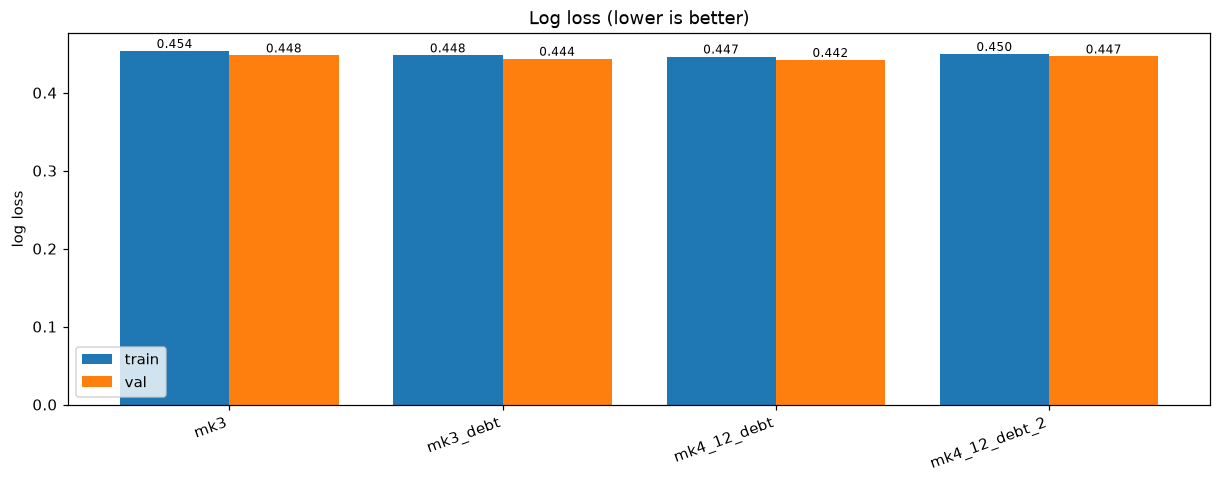
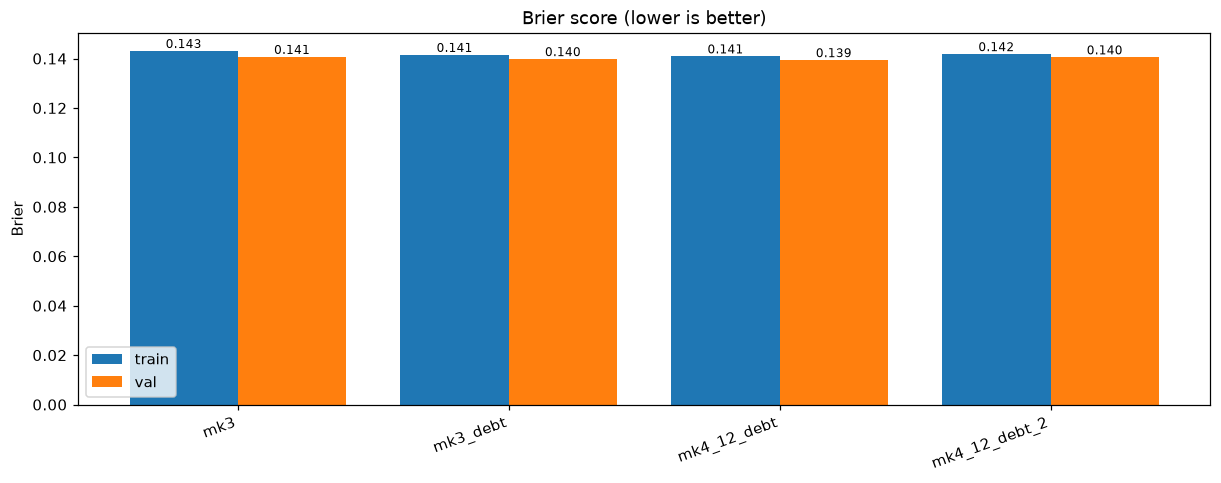

In [20]:

compare = {"mk3": mk3, "mk3_debt": mk3_debt, "mk4_12_debt": mk4_12_debt, "mk4_12_debt_2": mk4_12_debt_2}
thresholds = {n: 0.2 for n in compare}
show_row(
    lambda: plot_confusion(compare, split="val", thresholds=thresholds),
    lambda: plot_auc(compare),
    lambda: plot_logloss(compare),
    lambda: plot_brier(compare),
    width=800
)

**Interpretation**

| Model | $K$ | Val AUC | Val log loss | Val Brier | Recall at 0.2 | Specificity at 0.2 |
|---|---|---|---|---|---|---|
| `mk3` (no debt) | 3 | 0.737 | 0.448 | 0.141 | 62% | 78% |
| `mk3_debt` | 9 | 0.762 | 0.444 | 0.140 | 63% | 78% |
| `mk4_12_debt` | 12 | 0.762 | 0.442 | 0.139 | 63% | 79% |
| `mk4_12_debt_2` | 8 | 0.750 | 0.447 | 0.140 | 63% | 79% |

We can see clearly that the additional data has gains from the no debt model. The 3 util bins seems to be a more important split than an extra row as `mk3_debt` and `mk4_12_debt` have identical val AUC (0.762), with log loss and Brier scores within 0.002 and 0.001 respectively. While the `mk4_12_debt_2` has comparable probability confidence from log loss and brier scores, the AUC is noticeably lower (0.012 lower). The gains in AUC from base are larger than the gain in confidence of the models, so the debt information shows up mainly as a better ordering of customers rather than as better-calibrated probabilities. 

`mk3_debt` is the best trade-off: it ties for the highest AUC with the smallest number of states that achieves it, and its payment states are broad enough for the data to support most of the cells that matter. The difference between `mk3_debt` and `mk4_12_debt` is within noise, so the choice rests on parsimony rather than on a measured advantage.

## 5.8 Second-Order Chain

The last problem we identified in Section 5.4 is the one-step memory. A first-order chain sees only the previous month, so a customer who has been late for six months looks the same as one who has just slipped. As a final investigation, we test whether a second-order chain, in which the next state depends on the previous two months, gives significant gains over the previous models.

### 5.8.1 Model Definition

For class $k \in \{0, 1\}$ the second-order chain uses probabilities $P^{(2)}_k(z \mid a, b) = \Pr(x_{t+1}=z \mid x_{t-1}=a,\, x_t=b,\, y=k)$. With $K$ states this needs $K^3$ cells per class, so counts are much sparser than before. To keep the estimates stable, each row is shrunk towards the first-order chain:

$$
\hat P^{(2)}_k(z \mid a, b) \;=\; \frac{N_k(a,b,z) + \lambda\,\hat P^{(1)}_k(z \mid b)}{\sum_{z'} N_k(a,b,z') + \lambda},
\qquad
N_k(a,b,z) = \sum_{i \in \mathcal{D}_k} \sum_{t=2}^{T-1} \mathbf{1}[x_{i,t-1}=a,\; x_{i,t}=b,\; x_{i,t+1}=z],
$$

where $\hat P^{(1)}_k$ is the Laplace-smoothed first-order matrix from Section 5.6.1. The parameter $\lambda$ acts like $\lambda$ extra observations that follow the first-order chain: a pair of months $(a,b)$ seen only a few times falls back on the first-order estimate, while one seen often is dominated by its own counts. As $\lambda \to \infty$ the model reduces to the first-order chain. (Chen & Goodman, 1996)

The class score keeps the form used so far. Since the first transition has only one month of history, it still uses the first-order matrix, but each other transition will use the second-order one:

$$
s(\mathbf{x}) = \log\frac{\pi_1(x_1)}{\pi_0(x_1)}
+ \log\frac{\hat P^{(1)}_1(x_2 \mid x_1)}{\hat P^{(1)}_0(x_2 \mid x_1)}
+ \sum_{t=2}^{T-1} \log\frac{\hat P^{(2)}_1(x_{t+1} \mid x_{t-1}, x_t)}{\hat P^{(2)}_0(x_{t+1} \mid x_{t-1}, x_t)}
+ \log\frac{\hat p}{1-\hat p},
$$

the score is calibrated with Platt scaling on the validation set.


We use the 4-state `mk4_12` payment split, which gives $4^3 = 64$ cells per class and 16 two-month histories. A second-order chain on the 12-state debt model would need $12^3 = 1{,}728$ cells per class, far more than the data can support, so debt and memory are not combined. The second-order chain is compared with its own first-order version (`mk4_12`), which isolates the effect of memory, and with `mk3_debt`, the best model so far. 

In [21]:
def fit_chain2(S, K, alpha=1.0, lam=10.0):
    init = np.bincount(S[:, 0], minlength=K) + alpha
    init = init / init.sum()
    C1 = np.full((K, K), alpha)                                     # first-order, Laplace smoothed
    np.add.at(C1, (S[:, :-1].ravel(), S[:, 1:].ravel()), 1)
    P_first = C1 / C1.sum(1, keepdims=True)
    N = np.zeros((K, K, K))                                         # counts N[a, b, c]
    np.add.at(N, (S[:, :-2].ravel(), S[:, 1:-1].ravel(), S[:, 2:].ravel()), 1)
    P2 = (N + lam * P_first[None, :, :]) / (N.sum(2, keepdims=True) + lam)
    return init, P_first, P2, N

def llr2(S, m):
    sc = np.log(m["init1"][S[:, 0]]) - np.log(m["init0"][S[:, 0]])
    sc = sc + np.log(m["P_first1"][S[:, 0], S[:, 1]]) - np.log(m["P_first0"][S[:, 0], S[:, 1]])
    for t in range(1, S.shape[1] - 1):
        sc = sc + (np.log(m["P2_1"][S[:, t-1], S[:, t], S[:, t+1]])
                   - np.log(m["P2_0"][S[:, t-1], S[:, t], S[:, t+1]]))
    return sc + m["log_prior"]

def build_markov_order2(name, encode, K, labels=None, lam=10.0, alpha=1.0):
    """encode(df) -> integer state array of shape (n_customers, 6)."""
    S_tr, S_va, S_te = encode(train), encode(validation), encode(test)
    ytr = np.asarray(y_tr).astype(int)
    i0, F0, P0, N0 = fit_chain2(S_tr[ytr == 0], K, alpha, lam)      # TRAIN only
    i1, F1, P1, N1 = fit_chain2(S_tr[ytr == 1], K, alpha, lam)
    m = dict(name=name, K=K, labels=labels, lam=lam,
             init0=i0, init1=i1, P_first0=F0, P_first1=F1, P2_0=P0, P2_1=P1, N0=N0, N1=N1,
             log_prior=np.log(ytr.mean() / (1 - ytr.mean())))
    m["sc_tr"], m["sc_va"], m["sc_te"] = llr2(S_tr, m), llr2(S_va, m), llr2(S_te, m)
    m["platt"] = LogisticRegression(C=1e6).fit(m["sc_va"].reshape(-1, 1), y_va)   # VALIDATION only
    return m

In [22]:
base = states["mk4_12"]
enc = lambda d: base["to_state"](d[pay_cols].values)
mk4_12_o2 = build_markov_order2("mk4_12_order2", enc, base["K"], labels=base["labels"], lam=10)

0.1 0.7438
1 0.7438


10 0.7439
100 0.7429
10000.0 0.7376


100000000.0 0.7371
non-defaulters rows with <30 obs: 4 of 16
defaulters rows with <30 obs: 3 of 16



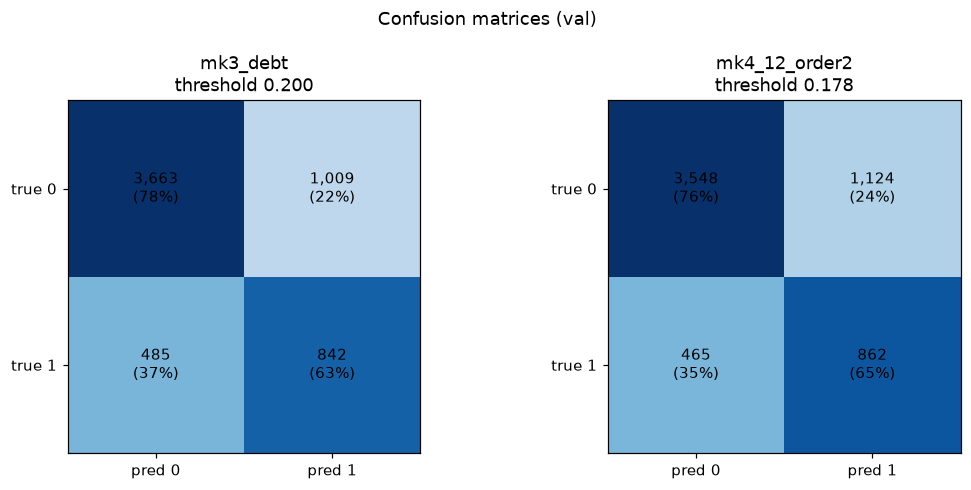
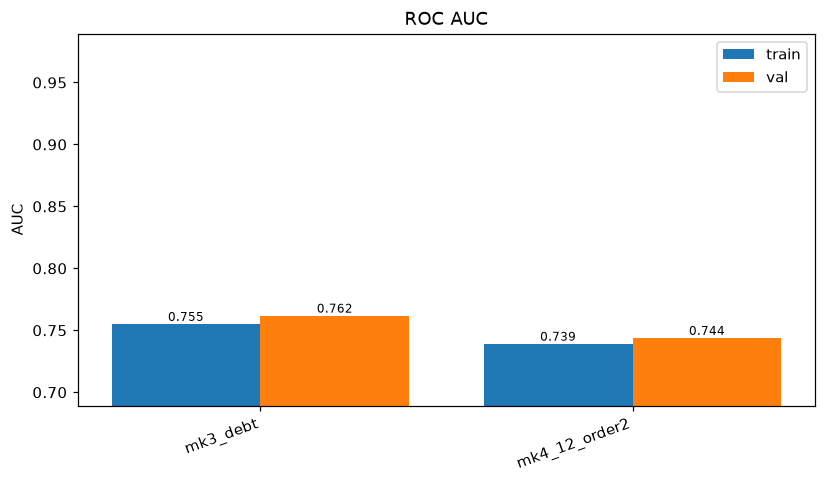
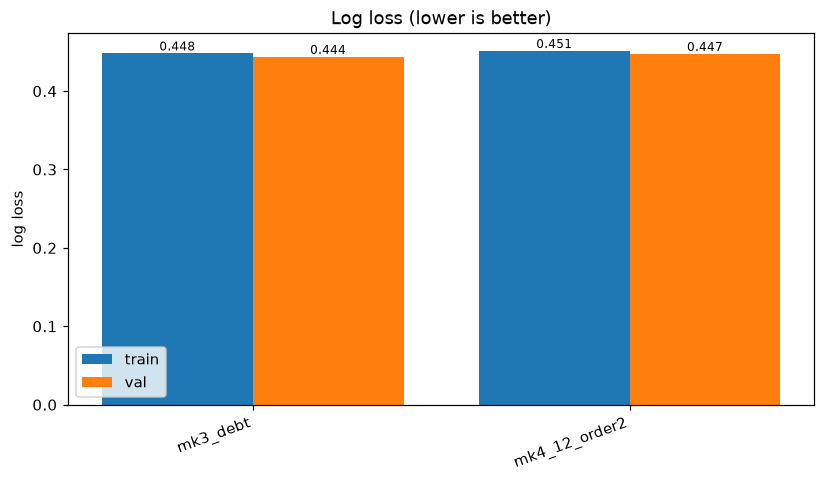
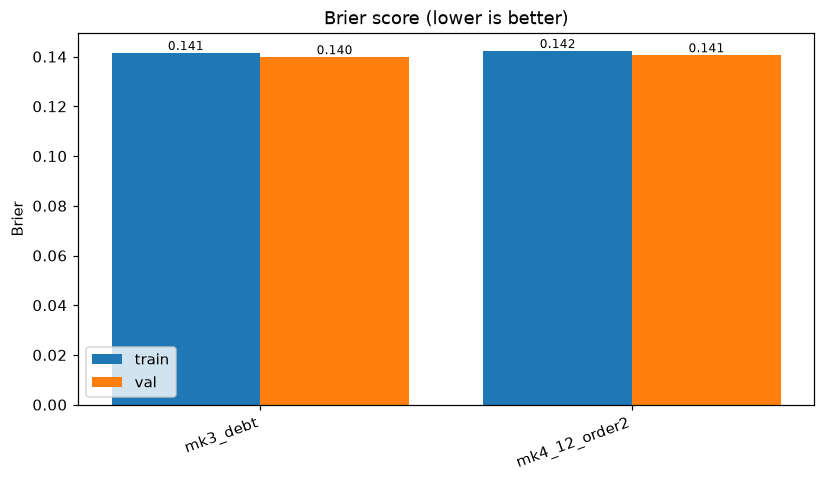

In [23]:
for lam in [0.1, 1, 10, 100, 1e4, 1e8]:
    m = build_markov_order2("o2", enc, base["K"], lam=lam)
    print(lam, round(roc_auc_score(y_va, m["sc_va"]), 4))

for c, N in [("non-defaulters", mk4_12_o2["N0"]), ("defaulters", mk4_12_o2["N1"])]:
    rows = N.sum(2)
    print(c, "rows with <30 obs:", int((rows < 30).sum()), "of", rows.size)
compare = {"mk3_debt": mk3_debt, "mk4_12_order2": mk4_12_o2}
show_row(
    lambda: plot_confusion(compare, split="val"),
    lambda: plot_auc(compare),
    lambda: plot_logloss(compare),
    lambda: plot_brier(compare ),
    width=500
)

**Interpretation**

Adding second-order memory increases the state-transition space to $K^3 = 64$ cells per class, leaving 3 of the 16 transition rows with fewer than 30 observations for defaulters (4 of 16 for non-defaulters). Even with shrinkage ($\lambda = 10$) towards the first-order transition matrix, `mk4_12_order2` underperforms `mk3_debt` on validation AUC, log loss, and Brier score. Augmenting a first-order chain with credit utilisation bins (`mk3_debt`) therefore captures more useful signal with better data support than increasing the chain order. Credit utilisation adds about 0.025 AUC to a first-order chain, whereas a second-order memory adds about 0.007 and needs four times as many cells, so does not seem worth continuing with. Wagner (2011) found that the second-order chain was the best which is not what we see here, however they do note that the margin is slim. With a larger dataset the second order may perform better as there would be less problems with scarcity.

## 5.9 Conclusion

In this section we have attempted to address some limitations of the baseline model with multiple different methods explored:

1. **Pooling the classes.** Fitting one chain per class was a clear improvement. Validation AUC rose from 0.710 to between 0.737 and 0.743, log loss and Brier score fell on every split, and the probabilities no longer under-predict risk for the highest-risk customers. Part of the calibration gain comes from Platt scaling, but the AUC gain does not.
2. **Compressed statuses.** Finer payment states barely help. The 5-state split is best on validation, but its edge over the coarser splits (about 0.005 AUC) is within sampling noise and rests on a sparse "1 late" row. A 3-state split (`mk3`) is as accurate in AUC as the 4-state `mk4_12` (0.737 for both), so whether a customer is late carries more weight than exactly how late.
3. **Missing amounts.** This was the largest single improvement. Adding three credit-utilisation bins raised validation AUC by about 0.025 (95% interval 0.016 to 0.034) with the same payment states, and the transition matrices show why: late defaulters stay late and revolving defaulters slide into late payment more often than non-defaulters, particularly at high utilisation. The gain is mainly in ranking; the probability metrics improve only slightly.
4. **One-step memory.** A second-order chain added about 0.007 AUC over its first-order version and did not match the debt model, while needing four times as many cells. A longer memory is not worth its sparsity here.

The table collects the validation results of every model examined, ordered by AUC. A constant prediction of the training default rate scores a log loss of about 0.528 and a Brier score of about 0.172 for reference. The two-class models' log loss and Brier scores are slightly optimistic, as their Platt scaling was fitted on the same validation customers.

| Model | States | Description | Val AUC | Val log loss | Val Brier |
|---|---|---|---|---|---|
| `pooled_onestep` | 4 | Baseline: one pooled chain | 0.710 | 0.458 | 0.144 |
| `mk4_12` | 4 | Two-class chain | 0.737 | 0.448 | 0.141 |
| `mk3` | 3 | Two-class chain | 0.737 | 0.448 | 0.141 |
| `mk4_nolate` | 4 | Two-class chain | 0.738 | 0.445 | 0.139 |
| `mk5_full` | 5 | Two-class chain | 0.743 | 0.444 | 0.139 |
| `mk4_12_order2` | 4 | Second-order two-class chain | 0.744 | 0.447 | 0.141 |
| `mk4_12_debt_2` | 8 | Two-class chain, 2 utilisation bins | 0.750 | 0.447 | 0.140 |
| **`mk3_debt`** | **9** | **Two-class chain, 3 utilisation bins** | **0.762** | **0.444** | **0.140** |
| `mk4_12_debt` | 12 | Two-class chain, 3 utilisation bins | 0.762 | 0.442 | 0.139 |

**Final model.** The chosen model is `mk3_debt`: a two-class first-order chain over nine states formed from three payment states (current/paid, revolving, late) and three utilisation bins, calibrated by Platt scaling. It ties for the best validation AUC with the smallest number of states, uses 81 transition cells per class (the rarer ones are greyed out as low-count in the heatmaps but carry few transitions), and every score can be traced back to individual transitions through the log-ratio heatmaps. Its advantage over `mk4_12_debt` is not distinguishable from noise, so it was chosen for parsimony.

## References

- Chen, S. F. & Goodman, J. (1996). An empirical study of smoothing techniques for language modeling. In *Proceedings of the 34th Annual Meeting of the Association for Computational Linguistics*, 310–318. https://arxiv.org/abs/cmp-lg/9606011
- Leow, M. & Crook, J. (2014). Intensity models and transition probabilities for credit card loan delinquencies. *European Journal of Operational Research* 236(2), 685–694. https://doi.org/10.1016/j.ejor.2013.12.026
- Malik, M. & Thomas, L. C. (2012). Transition matrix models of consumer credit ratings. *International Journal of Forecasting* 28(1), 261–272. https://doi.org/10.1016/j.ijforecast.2011.01.007
- Platt, J. C. (1999). Probabilistic outputs for support vector machines and comparisons to regularized likelihood methods. In A. J. Smola et al. (eds), *Advances in Large Margin Classifiers*, 61–74. MIT Press.
- Wagner, F. (2011). *Markov-Chain based Credit Control for Subscribers to Mobile Communication Services*. Credit Research Centre, University of Edinburgh. https://cer.business-school.ed.ac.uk/wp-content/uploads/sites/55/2017/03/Markov-Chain-Based-Credit-Control-Wagner.pdf
